<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/11_Vulnerability_Software_Supply_Chain_Attacks/QCNN_JavaVulnerability_Hussain2024.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# QCNN with self-attentive pooling for Java vulnerability detection: Hussain et al. (2024) step by step

This notebook re-implements, runs and checks the method of

> Shumaila Hussain, Muhammad Nadeem, Junaid Baber, Mohammed Hamdi, Adel Rajab, Mana Saleh Al Reshan and Asadullah Shaikh,
> "Vulnerability detection in Java source code using a quantum convolutional neural network with self-attentive pooling, deep
> sequence, and graph-based hybrid feature extraction", *Scientific Reports* 14, 7406 (2024).
> https://doi.org/10.1038/s41598-024-56871-z

The paper's data-availability statement points to a GitHub repository (`Vul-Detect-Code/Vul-Detect`); at the time of writing it
holds no code and no data (6 KB), so everything below is written from the method as the paper describes it.

**What the notebook does.** It downloads the public NIST *Juliet Java 1.3* test suite (the Java part of the SARD benchmark that the paper
uses), cuts it into single Java methods labelled vulnerable (`bad()`) or safe (`good*()`), removes the words that would give the label away,
and builds the paper's *hybrid features*: a **sequence branch** (greedy longest-match-first word pieces, the tokenisation the paper names) and a
**graph branch** (a statement graph with syntax-tree, control-flow and control/data-dependence edges, node2vec-style node embeddings, graph
convolution, recursive feature elimination with a decision tree). The two branches are concatenated, reduced to one feature per qubit and fed to a
**quantum convolutional neural network with self-attentive pooling**, simulated exactly in PennyLane. A classical baseline (random forest, SVC, Keras
MLP, CNN and LSTM) is trained on exactly the same inputs, and the last section puts the paper's numbers next to ours with a verdict per claim.

**How to run it.** Open it in Colab (badge above), choose a CPU runtime and use *Runtime -> Run all*. The committed outputs come from `FAST_MODE = False` (full budgets of the configuration cell, about 50 minutes on a shared 4-core CPU); `FAST_MODE = True` is a class demo of about 10 minutes. No account, token or API
key is needed: Juliet is downloaded from public GitHub mirrors. A Hugging Face token is not used.

**What you get at the end.** Dataset plots of the real functions, drawings of the circuits that are really executed (with an exactness check
against an independent state-vector simulation), a table of binary and 5-class results with seeds, and a claim-by-claim comparison with the paper.

## The paper in one page

**Problem.** Find vulnerable Java code automatically. Existing deep-learning detectors depend on language-specific tooling, ignore code semantics,
detect at coarse granularity and struggle with long code; the authors want a fine-grained Java detector that uses both syntax and semantics.

**Decision.** For a Java function: vulnerable or not, and which type (improper input validation, SQL injection, missing authorisation, cross-site
scripting, buffer/integer overflow, all from the CWE Top-25).

**Method.** (1) Intermediate representation: a code property graph (AST + control-flow graph + program-dependence graph) and tokens.
(2) Graph features: node2vec node embeddings, then a hybrid GCN-RFEMLP (graph convolution with a bi-affine layer, multilayer perceptron with a
recursive-feature-elimination wrapper using a decision tree). (3) Sequence features: CodeBERT, fine-tuned (batch 32, learning rate 1e-3, 50 epochs),
tokenised with the greedy longest-match-first algorithm. (4) The two feature sets are concatenated, converted to binary features and **basis-encoded**
into a four-qubit PennyLane device ("the RY gate converts the code into quantum bits"). (5) A **QCNN** (random quantum circuits as convolution and
pooling layers, MERA-like reduction) whose pooling layer is made *self-attentive* with tokenisation, multi-head self-attention, spatial channel
restoration and sigmoid/softmax activations, followed by a decoding circuit that classifies the code and the vulnerability type.

**Data.** SARD (46,447 selected Java programs; the text also lists 42,212 files with 29,258 safe and 12,954 unsafe samples). Validation sets: Juliet Java 1.3,
FUNDED, Vul4J, CVEfixes, CodeXGLUE (and VUDDY in Table 4).

**Preprocessing.** Balance classes, remove duplicate code (decision trees), handle outliers (log transform), vectorise, z-scale.

**Training set-up.** Epochs 50, learning rate 0.005, momentum 0.9, dropout 0.3, cross-entropy; the MLP part: 300 epochs, 128 neurons, learning rate 0.0005,
early stopping 30, batch 64, SGD + MSE ("selection 7" of Table 2).

**Claims.**

| Claim | Where | Value |
|---|---|---|
| Accuracy of the proposed system | abstract, Table 3 | 99.2 % (0.99) |
| F1 / precision / recall | Table 5 | 0.97 / 0.98 / 0.96 |
| Per-dataset precision / recall / F1 (SARD, Juliet Java 1.3) | Table 4 | 0.98 / 0.97 / 0.95 ; 0.98 / 0.95 / 0.96 |
| Classical rivals (accuracy) | Table 3 | CNN 0.92, SVM 0.96, GNN 0.95, LSTM 0.96, BiLSTM 0.96, ANN 0.98, MLP 0.84, DNN 0.82, FFDNN 0.77 |
| Other datasets | Table 4 | FUNDED, Vul4J, CVEfixes, CodeXGLUE, VUDDY: P 0.92-0.98, F1 0.91-0.99 |
| Hybrid features and self-attentive pooling help | contributions | qualitative (no ablation reported) |

## What follows the paper and what had to be chosen

The paper is silent or relies on tools we cannot run here (CodeBERT fine-tuning, a Java code-property-graph extractor, the exact SARD file list). Every
choice is marked `# CHOICE:` in the code below.

| Item | Paper | This notebook |
|---|---|---|
| Data | SARD, 46,447 Java programs, five CWE groups | NIST Juliet Java 1.3 (SARD test suite 111) from two public GitHub mirrors; single-file flow variants only (`..._01` to `..._22` files); four weakness families: SQL injection (CWE-89), cross-site scripting (CWE-80/81/83), improper input validation (CWE-129/606), integer overflow (CWE-190/191). Juliet Java has **no missing-authorisation** directory |
| Sample | "vulnerable functions" | one Java method per sample: `bad()` = vulnerable, `goodG2B*`/`goodB2G*` = safe |
| Size | about 46,000 programs | `FAST_MODE`: about 2,100 unique functions; full: about 5,500 (after de-duplication, balanced 50/50) |
| Cleaning | balance, duplicate removal with decision trees, log transform of outliers, vectorise, z-scale | comments removed, identifiers containing "bad"/"good" masked (otherwise the label leaks), exact duplicates of the token sequence removed (and sequences that carry both labels dropped), classes balanced by undersampling, z-scaling of the features; no log transform (no heavy-tailed raw counts) |
| Graph | CPG: AST + CFG + PDG (tool not named) | regex statement graph with AST, CFG, control-dependence and data-dependence edges (no Java parser needed) |
| Node embedding | node2vec | node2vec's biased random walks on the graph of node *types*, skip-gram implemented as shifted-PPMI + SVD (8 dims) |
| Graph network | GCN + bi-affine layer, MLP + RFE (decision tree), SGD+MSE | parameter-free two-hop GCN propagation with mean/max read-out, then RFE with a decision tree to 12 features; the paper's MLP appears as a Keras baseline |
| Sequence model | CodeBERT, fine-tuned | **not run** (needs `transformers` and a 500 MB model): word-piece vocabulary + greedy longest-match-first encoding, TF-IDF over pieces and bigrams, truncated SVD to 16 dims |
| Fusion | concatenation, binarise | concatenation (28 dims), z-scaling, RFE with a decision tree to one feature per qubit |
| Qubits | "four-qubit device" | 8 qubits: four bits can represent only 16 different inputs |
| Encoding | basis encoding of binary features; RY | both: **basis** (features thresholded at their training medians) and **RY angle** (features min-max scaled to [0, pi]) |
| QCNN | conv + pooling random circuits, self-attentive pooling, fully connected decoding | 6-parameter two-qubit convolution filter, controlled-rotation pooling whose strength is multiplied by an attention gate; gates come from multi-head self-attention over the per-qubit expectation values |
| Optimiser | lr 0.005, momentum 0.9, dropout 0.3, cross-entropy, 50 epochs | Adam, learning rate 0.05 and cross-entropy for the circuit (budgets in the configuration cell); the paper's SGD recipe for the Keras baselines |
| Split | not stated | stratified 75 % / 25 % |
| Metrics | accuracy, precision, recall, F1 | same, vulnerable = positive class |

## 0. Setup

In [1]:
# Versions tested with this notebook (October 2026). Colab already ships numpy, pandas, scikit-learn, matplotlib, networkx and tensorflow.
# The pip line runs on Colab (or wherever PennyLane is missing); a prepared local environment is left untouched.
import importlib.util, sys
IN_COLAB = importlib.util.find_spec("google.colab") is not None
if IN_COLAB or importlib.util.find_spec("pennylane") is None:
    %pip install -q "pennylane==0.45.1" networkx
    print("Packages installed. If Colab asks you to restart the session, do so and run all cells again.")
else:
    print("PennyLane already present; skipping pip install.")

PennyLane already present; skipping pip install.


In [2]:
# ---------------- configuration ----------------
FAST_MODE = False        # True: class demo of about 10 minutes. False: larger budgets (about 1 hour on a shared 4-core CPU).
SEED      = 42            # CHOICE: the paper gives no seed
N_QUBITS  = 8             # CHOICE: one feature per qubit (the paper simulates "a four-qubit device")
D_SEQ     = 16            # CHOICE: dimension of the sequence embedding (CodeBERT gives 768)
D_NODE    = 8             # CHOICE: node2vec dimension
K_GRAPH   = 12            # CHOICE: graph features kept by the first RFE
TEST_SIZE = 0.25          # CHOICE: the paper does not state its split
LR_Q      = 0.05          # CHOICE: Adam learning rate of the circuit (the paper's 0.005 is for SGD with momentum)

if FAST_MODE:
    N_PER_FAMILY  = 400   # raw bad() and good*() functions drawn per family before de-duplication
    QUANTUM_TRAIN = 200   # functions the circuit is trained on (class balanced); the baselines use the whole training split
    EPOCHS_Q, BATCH_Q = 14, 100
    Q_SEEDS, BASE_SEEDS, KERAS_SEEDS, KERAS_EPOCHS, KERAS_BATCH = [42], [42], [42], 30, 64
else:
    N_PER_FAMILY  = 1500
    QUANTUM_TRAIN = 400
    EPOCHS_Q, BATCH_Q = 25, 50
    Q_SEEDS, BASE_SEEDS, KERAS_SEEDS, KERAS_EPOCHS, KERAS_BATCH = [42, 43], [42, 43, 44], [42, 43], 50, 128   # paper: 50 epochs

DATA_DIR = "data"         # downloaded data is cached here (relative to the working directory)
IBM_TOKEN = ""            # not used: the circuits are simulated exactly; no real-hardware cell in this notebook

In [3]:
import os, re, time, zipfile, hashlib, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD, PCA
from sklearn.feature_selection import RFE
from sklearn.tree import DecisionTreeClassifier
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report
import sklearn, networkx as nx
import pennylane as qml
import tensorflow as tf

os.makedirs(DATA_DIR, exist_ok=True)
rng = np.random.default_rng(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
print("numpy", np.__version__, "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__, "| networkx", nx.__version__)
print("pennylane", qml.__version__, "| tensorflow", tf.__version__, "| FAST_MODE =", FAST_MODE)

numpy 2.5.4 | pandas 3.0.6 | scikit-learn 1.9.1 | networkx 3.7
pennylane 0.45.1 | tensorflow 2.21.0 | FAST_MODE = False


## 1. The data: Juliet Java 1.3 (SARD)

SARD, the NIST Software Assurance Reference Dataset, holds thousands of synthetic test programs with known weaknesses. Its Java part is the *Juliet Test
Suite 1.3 for Java*: for every weakness (CWE) a set of generated programs that combine a **source** of data, a **sink** that uses it and a **control- or
data-flow variant** (numbered `01` to `22` for single-file programs, `51a/51b`... for multi-file ones). Each program has a `bad()` method that contains the
weakness and `goodG2B()` / `goodB2G()` methods (good source + bad sink, bad source + good sink) that do not. That naming is the ground truth: `bad` = vulnerable,
`good*` = safe.

The suite is downloaded as a 65 MB zip from GitHub, the methods we need are cut out, and the archive is deleted again. The cut-out sample is cached in `DATA_DIR`.

**Sampling.** Juliet is extremely repetitive (many flow variants produce the same code after comments are removed). Files are read in random order until each family
has `N_PER_FAMILY` vulnerable and `N_PER_FAMILY` safe methods; exact duplicates are removed afterwards.

**Not an arbitrary choice.** Juliet files contain the comments `POTENTIAL FLAW` and `FIX`, and the methods are called `bad`/`good...`: both would give the label away,
so comments are removed and identifiers containing "bad" or "good" are replaced by `FUNC` before any feature is computed.

In [4]:
import re, zipfile, io, gzip, json, hashlib, collections

JULIET_URLS = [  # CHOICE: two public GitHub mirrors of the NIST SARD Juliet Java 1.3 test suite (suite 111)
    "https://github.com/find-sec-bugs/juliet-test-suite/archive/refs/heads/master.zip",
    "https://github.com/UnitTestBot/juliet-java-test-suite/archive/refs/heads/master.zip",
]
# CHOICE: the paper's five weakness groups mapped onto the Juliet Java CWE directories that exist.
# "Missing authorization" has no Juliet Java directory, so only four vulnerability families can be built.
FAMILIES = {
    "SQL injection":            ["CWE89"],
    "Cross-site scripting":     ["CWE80", "CWE81", "CWE83"],
    "Improper input validation": ["CWE129", "CWE606"],
    "Integer overflow":         ["CWE190", "CWE191"],
}
CWE_TO_FAMILY = {c: f for f, cs in FAMILIES.items() for c in cs}
TYPE_NAMES = ["safe"] + list(FAMILIES)            # 5 classes; index = class id used everywhere below

FILE_RE   = re.compile(r"/(CWE\d+)_[^/]*/(?:s\d+/)?[^/]*_(\d{2})\.java$")      # single-file flow variants only
METHOD_RE = re.compile(r"(?:public|private|protected)\s+(?:static\s+)?(?:final\s+)?[\w<>\[\],.]+\s+(\w+)\s*\([^)]*\)\s*(?:throws\s+[\w.,\s]+)?\{")
ENTRY_RE  = re.compile(r"^(bad|good(?:G2B|B2G)?\d*)$")                          # entry methods only, not helper "*Sink" methods
CMT_STR   = re.compile(r'//[^\n]*|/\*.*?\*/|"(?:\\.|[^"\\\n])*"|\'(?:\\.|[^\'\\\n])*\'', re.S)

def strip_comments(src):
    """Remove // and /* */ comments (they contain the words FLAW / FIX, i.e. the label) but keep string literals."""
    return CMT_STR.sub(lambda m: m.group(0) if m.group(0)[0] in "\"'" else " ", src)

def match_brace(src, start):
    """Index of the } that closes the { at src[start]; braces inside string literals are ignored."""
    depth, i, n = 0, start, len(src)
    while i < n:
        ch = src[i]
        if ch in "\"'":
            q = ch; i += 1
            while i < n and src[i] != q:
                i += 2 if src[i] == "\\" else 1
        elif ch == "{": depth += 1
        elif ch == "}":
            depth -= 1
            if depth == 0: return i
        i += 1
    return -1

def methods_of(src):
    src = strip_comments(src)
    for m in METHOD_RE.finditer(src):
        name = m.group(1)
        if not ENTRY_RE.match(name) or name == "good":     # "good()" only calls goodG2B()/goodB2G(): not a sample
            continue
        end = match_brace(src, m.end() - 1)
        if end < 0: continue
        yield name, src[m.end():end]

def download_juliet(zip_path):
    import requests
    last = None
    for url in JULIET_URLS:
        try:
            with requests.get(url, stream=True, timeout=120) as r:
                r.raise_for_status()
                with open(zip_path, "wb") as f:
                    for chunk in r.iter_content(1 << 20): f.write(chunk)
            print("downloaded", url, f"({os.path.getsize(zip_path)/1e6:.0f} MB)")
            return
        except Exception as e:
            last = e; print("mirror failed:", url, type(e).__name__)
    raise RuntimeError(f"no Juliet mirror reachable: {last}")

def build_raw_functions(n_target_per_family, seed):
    """Read Juliet Java files in random order and keep bad()/good*() entry methods until every family has
    n_target_per_family vulnerable and n_target_per_family safe functions (before de-duplication)."""
    cache = os.path.join(DATA_DIR, f"juliet_java_functions_{n_target_per_family}_{seed}.csv.gz")
    if os.path.exists(cache):
        print("using cached", cache); return pd.read_csv(cache)
    zip_path = os.path.join(DATA_DIR, "juliet_java.zip")
    if not os.path.exists(zip_path): download_juliet(zip_path)
    z = zipfile.ZipFile(zip_path)
    files = collections.defaultdict(list)
    for n in z.namelist():
        m = FILE_RE.search(n)
        if m and m.group(1) in CWE_TO_FAMILY: files[CWE_TO_FAMILY[m.group(1)]].append((n, m.group(1)))
    rng_ = np.random.default_rng(seed)
    rows = []
    for fam, lst in files.items():
        lst = [lst[i] for i in rng_.permutation(len(lst))]
        got = {0: 0, 1: 0}
        for name, cwe in lst:
            if got[0] >= n_target_per_family and got[1] >= n_target_per_family: break
            src = z.read(name).decode("utf-8", "replace")
            for mname, body in methods_of(src):
                lab = 1 if mname == "bad" else 0
                if got[lab] >= n_target_per_family: continue
                rows.append(dict(file=name.split("/")[-1], cwe=cwe, family=fam, method=mname, label=lab, code=body)); got[lab] += 1
    z.close()
    df_ = pd.DataFrame(rows)
    df_.to_csv(cache, index=False, compression="gzip")
    os.remove(zip_path)                      # the 65 MB archive is not kept
    print("cached", cache, f"({os.path.getsize(cache)/1e6:.1f} MB)")
    return df_

The helper functions of the next sections (lexer, word pieces, statement graph, node2vec, graph convolution) are defined here once; section 2 explains them.

In [5]:
from functools import lru_cache
from collections import Counter, defaultdict

# ------------------------------------------------------------------ sequence side: lexer + greedy longest-match-first word pieces
TOK_RE = re.compile(r'"(?:\\.|[^"\\\n])*"|\'(?:\\.|[^\'\\\n])*\'|[A-Za-z_]\w*|\d+(?:\.\d+)?|==|!=|<=|>=|&&|\|\||\+\+|--|\+=|-=|[^\s\w]')
LEAK_RE = re.compile(r"\w*(?:bad|good)\w*", re.I)

def normalise_code(code):
    """Remove the identifiers that carry the label (bad..., good...): they are not part of real vulnerable code."""
    return LEAK_RE.sub("FUNC", code)

def lex(code):
    out = []
    for t in TOK_RE.findall(code):
        if t[0] in "\"'":
            out.append('"'); out += re.findall(r"\w+|[^\s\w]", t[1:-1]); out.append('"')
        elif t[0].isdigit():
            out.append(t if len(t) <= 2 else "<NUM>")
        else:
            out.append(t)
    return out

class GreedyWordPiece:
    """WordPiece-style vocabulary learned on the TRAINING functions, encoded with the greedy longest-match-first
    algorithm the paper names (CodeBERT tokeniser). Whole frequent tokens, frequent in-word character n-grams
    (continuation pieces, prefix ##) and single characters make up the vocabulary."""
    def fit(self, token_lists, n_words=400, n_pieces=300):
        cnt = Counter(t for ts in token_lists for t in ts)
        words = [w for w, _ in cnt.most_common(n_words)]
        pc = Counter()
        for w, c in cnt.items():
            if w in words or not w[0].isalpha(): continue
            for n in range(2, 6):
                for i in range(1, len(w) - n + 1): pc[w[i:i + n]] += c
        self.vocab = set(words) | {"##" + p for p, _ in pc.most_common(n_pieces)}
        chars = {ch for w in cnt for ch in w}
        self.vocab |= chars | {"##" + ch for ch in chars}
        self._enc = lru_cache(maxsize=None)(self._encode_token)
        return self
    def _encode_token(self, tok):
        out, start = [], 0
        while start < len(tok):
            end = len(tok); piece = None
            while end > start:
                cand = tok[start:end] if start == 0 else "##" + tok[start:end]
                if cand in self.vocab: piece = cand; break
                end -= 1
            if piece is None: return ("[UNK]",)
            out.append(piece); start = end
        return tuple(out)
    def encode(self, tokens):
        return [p for t in tokens for p in self._enc(t)]

def piece_analyzer(pieces):                                   # unigrams + bigrams of word pieces (keeps a little order information)
    return pieces + [a + " " + b for a, b in zip(pieces, pieces[1:])]

# ------------------------------------------------------------------ graph side: statement-level code property graph (regex based)
KW = {"if", "else", "for", "while", "do", "switch", "case", "default", "try", "catch", "finally", "return", "throw", "break",
      "continue", "synchronized", "new", "int", "long", "short", "byte", "char", "float", "double", "boolean", "String",
      "null", "true", "false", "final", "static", "void", "this", "throws", "instanceof"}
IDENT = re.compile(r"[A-Za-z_]\w*")
DECL_RE = re.compile(r"^(?:final\s+)?[\w.<>\[\],]+(?:\s*\[\s*\])*\s+[A-Za-z_]\w*\s*(?:\[\s*\]\s*)?(?:=|;|$)")
ASSIGN_RE = re.compile(r"^(?:final\s+)?(?:[\w.<>\[\],]+(?:\s*\[\s*\])*\s+)?([A-Za-z_]\w*)\s*(?:\[[^\]]*\]\s*)?(?:=|\+=|-=|\*=|/=|%=)(?!=)")
CALL_RE = re.compile(r"\b([A-Za-z_]\w*)\s*\(")
ARITH_RE = re.compile(r"(?<![+\-])[+\-*/%](?![+\-=])|\+\+|--|\+=|-=|\*=")
CASE_RE = re.compile(r"^(?:case\s+[^:]+:|default\s*:)\s*")

def split_statements(code):
    """Yield ('stmt'|'open'|'close', text). A ';' ends a statement only outside parentheses; braces that follow '=' or ']' belong
    to an array initialiser and stay in the statement text."""
    ev, buf, pd, i, n = [], [], 0, 0, len(code)
    while i < n:
        ch = code[i]
        if ch in "\"'":
            j = i + 1
            while j < n and code[j] != ch: j += 2 if code[j] == "\\" else 1
            buf.append(code[i:j + 1]); i = j + 1; continue
        if ch == "(": pd += 1
        elif ch == ")": pd -= 1
        if pd <= 0 and ch == ";":
            t = "".join(buf).strip(); buf = []
            if t: ev.append(("stmt", t))
        elif ch == "{":
            t = "".join(buf).strip()
            if pd <= 0 and (t.endswith("=") or t.endswith("]") or t.endswith(",")) :
                j, d = i, 0
                while j < n:
                    if code[j] == "{": d += 1
                    elif code[j] == "}":
                        d -= 1
                        if d == 0: break
                    j += 1
                buf.append(code[i:j + 1]); i = j + 1; continue
            ev.append(("open", t)); buf = []
        elif ch == "}" and pd <= 0:
            t = "".join(buf).strip(); buf = []
            if t: ev.append(("stmt", t))
            ev.append(("close", ""))
        else:
            buf.append(ch)
        i += 1
    return ev

def kind_of(text):
    t = CASE_RE.sub("", text).strip()
    w = (IDENT.match(t).group(0) if IDENT.match(t) else "")
    if t == "": return "block"
    if w == "else": return "else" if t == "else" else "if"
    if w in {"if", "for", "while", "do", "switch", "try", "catch", "finally", "return", "throw", "break", "continue", "synchronized"}: return w
    if DECL_RE.match(t): return "decl"
    if ASSIGN_RE.match(t): return "assign"
    if "(" in t: return "call"
    return "other"

def build_graph(code):
    """Return (node_type_strings, edges) with edges = {'ast','cfg','cdep','ddep'} lists of (src, dst). Node 0 is the method root."""
    nodes = [("method", "")]
    parent = [-1]; edges = {"ast": [], "cfg": [], "cdep": [], "ddep": []}
    stack = [0]; kids = defaultdict(list); is_hdr = {0: True}
    for typ, text in split_statements(code):
        if typ == "close":
            if len(stack) > 1: stack.pop()
            continue
        text = CASE_RE.sub("", text).strip()
        k = kind_of(text) if typ == "stmt" else (kind_of(text) if text else "block")
        nid = len(nodes); nodes.append((k, text)); parent.append(stack[-1])
        edges["ast"].append((stack[-1], nid)); kids[stack[-1]].append(nid)
        if stack[-1] != 0: edges["cdep"].append((stack[-1], nid))
        if typ == "open": stack.append(nid); is_hdr[nid] = True
    # control-flow edges: siblings in order, header -> first child, last child -> next sibling (and back to loop headers)
    def exit_node(h):
        while kids.get(h): h = kids[h][-1]
        return h
    for h, ch in kids.items():
        if h != 0 and ch: edges["cfg"].append((h, ch[0]))                  # enter the block
        for a, b in zip(ch, ch[1:]):
            edges["cfg"].append((a, b))                                     # fall through / branch not taken / loop exit
            if kids.get(a): edges["cfg"].append((exit_node(a), b))          # leave the block of a compound statement
        if h != 0 and nodes[h][0] in {"for", "while", "do"} and ch: edges["cfg"].append((exit_node(h), h))   # loop back edge
    if kids.get(0): edges["cfg"].append((0, kids[0][0]))
    # data-dependence edges: flow-insensitive "last definition reaches the use" in textual order
    last_def, defd = {}, set()
    for nid in range(1, len(nodes)):
        k, t = nodes[nid]
        d = set()
        m = ASSIGN_RE.match(t)
        if m: d.add(m.group(1))
        if k == "for":
            m2 = re.search(r"\(\s*(?:[\w<>\[\]]+\s+)?([A-Za-z_]\w*)\s*=", t)
            if m2: d.add(m2.group(1))
        if k == "catch":
            ids = IDENT.findall(t); d.add(ids[-1]) if ids else None
        for a, b in re.findall(r"([A-Za-z_]\w*)\s*(?:\+\+|--)|(?:\+\+|--)\s*([A-Za-z_]\w*)", t): d.add(a or b)
        for v in {x for x in IDENT.findall(t)} - KW:
            if v in last_def and last_def[v] != nid: edges["ddep"].append((last_def[v], nid))
        for v in d: last_def[v] = nid
    types = ["method"]
    for k, t in nodes[1:]:
        tt = CASE_RE.sub("", t)
        callee = ""
        for c in CALL_RE.findall(tt):
            if c not in KW: callee = c; break
        flags = ("A" if ARITH_RE.search(tt) else "") + ("I" if re.search(r"\w\s*\[\s*[\w\-]", tt) and k not in ("decl",) else "") + \
                ("C" if k in {"if", "while", "for"} and re.search(r"[<>]|==|!=", tt) else "") + ("S" if '"' in tt else "")
        types.append(f"{k}|{callee}|{flags}")
    return types, edges

class TypeNode2Vec:
    """node2vec on the node-TYPE graph accumulated over the training graphs: biased second-order random walks (p, q) are
    turned into skip-gram co-occurrence counts, and the shifted-PPMI matrix is factorised with an SVD (this is the matrix
    that skip-gram with negative sampling implicitly factorises, Levy and Goldberg 2014)."""
    def fit(self, type_lists, edge_lists, dim=8, walks=10, length=20, window=3, p=1.0, q=0.5, min_count=15, seed=42):
        cnt = Counter(t for ts in type_lists for t in ts)
        self.types = [t for t, c in cnt.most_common() if c >= min_count][:150]
        self.idx = {t: i for i, t in enumerate(self.types)}
        T = len(self.types); W = np.zeros((T, T))
        for ts, es in zip(type_lists, edge_lists):
            for kind in es:
                for a, b in es[kind]:
                    ia, ib = self.idx.get(ts[a]), self.idx.get(ts[b])
                    if ia is not None and ib is not None and ia != ib: W[ia, ib] += 1; W[ib, ia] += 1
        r = np.random.default_rng(seed)
        nbr = [np.nonzero(W[i])[0] for i in range(T)]
        C = np.zeros((T, T))
        for start in range(T):
            for _ in range(walks):
                walk = [start]
                while len(walk) < length:
                    v = walk[-1]
                    if len(nbr[v]) == 0: break
                    w = W[v, nbr[v]].copy()
                    if len(walk) > 1:
                        t_ = walk[-2]
                        w = w * np.where(nbr[v] == t_, 1 / p, np.where(W[t_, nbr[v]] > 0, 1.0, 1 / q))
                    walk.append(r.choice(nbr[v], p=w / w.sum()))
                for i, a in enumerate(walk):
                    for b in walk[max(0, i - window):i + window + 1]:
                        if b != a: C[a, b] += 1
        tot = C.sum() + 1e-9; pa = C.sum(1, keepdims=True) / tot; pb = C.sum(0, keepdims=True) / tot
        with np.errstate(divide="ignore", invalid="ignore"):
            ppmi = np.maximum(np.log((C / tot) / (pa * pb + 1e-12) + 1e-12), 0)
        U, S_, _ = np.linalg.svd(ppmi, full_matrices=False)
        self.E = U[:, :dim] * np.sqrt(S_[:dim]); self.dim = dim
        return self
    def embed(self, types):
        return np.array([self.E[self.idx[t]] if t in self.idx else np.zeros(self.dim) for t in types])

EDGE_KINDS = ["ast", "cfg", "cdep", "ddep"]
def graph_vector(types, edges, n2v, hops=2):
    """Parameter-free GCN propagation (A_hat^hops X, A_hat = D^-1/2 (A+I) D^-1/2) over AST+CFG+control+data edges, then
    mean/max readout. Node features = type embedding + normalised degree per edge kind."""
    n = len(types); A = np.eye(n)
    deg = np.zeros((n, len(EDGE_KINDS)))
    for k, kind in enumerate(EDGE_KINDS):
        for a, b in edges[kind]: A[a, b] = A[b, a] = 1; deg[a, k] += 1; deg[b, k] += 1
    d = A.sum(1); Ah = A / np.sqrt(np.outer(d, d))
    X = np.hstack([n2v.embed(types), np.log1p(deg)])
    H = X
    for _ in range(hops): H = Ah @ H
    return np.concatenate([H.mean(0), H.max(0), [np.log1p(n)], np.log1p([len(edges[k]) for k in EDGE_KINDS])])

Download, cut out the methods, clean, de-duplicate, balance and split. Every fitted transform in the next sections sees the training split only.

In [6]:
t0 = time.time()
raw = build_raw_functions(N_PER_FAMILY, SEED)
print(f"loaded {len(raw):,} Java functions in {time.time()-t0:.0f} s")
print("columns:", list(raw.columns))
print(raw.groupby(["family", "label"]).size().unstack().rename(columns={0: "good*() = safe", 1: "bad() = vulnerable"}))

downloaded https://github.com/find-sec-bugs/juliet-test-suite/archive/refs/heads/master.zip (65 MB)


cached data\juliet_java_functions_1500_42.csv.gz (0.6 MB)
loaded 10,908 Java functions in 26 s
columns: ['file', 'cwe', 'family', 'method', 'label', 'code']
label                      good*() = safe  bad() = vulnerable
family                                                       
Cross-site scripting                 1296                 792
Improper input validation            1500                1500
Integer overflow                     1500                1500
SQL injection                        1500                1320


In [7]:
# Step 1 of the paper's preprocessing: remove comments (done at extraction), remove label-bearing identifiers, de-duplicate.
raw["code_n"] = raw.code.map(normalise_code)                       # identifiers containing 'bad'/'good' -> FUNC
raw["tokens"] = raw.code_n.map(lex)
raw["key"] = raw.tokens.map(lambda t: hashlib.md5(" ".join(t).encode()).hexdigest())
conflict = raw.groupby("key").label.nunique()
n_conflict = int((conflict > 1).sum())
clean = raw[~raw.key.isin(conflict[conflict > 1].index)].drop_duplicates("key").reset_index(drop=True)
print(f"raw {len(raw):,} -> {len(raw)-len(raw.drop_duplicates('key')):,} exact duplicates removed, "
      f"{n_conflict} token sequences carried both labels and were dropped -> {len(clean):,} unique functions")

# Step 2: class balance. Every vulnerable (bad) function is kept; the safe class (good* methods of all four families) is
# undersampled at random to the same size, so the binary task is 50 / 50 as in the paper's "dataset balancing" step.
vul = clean[clean.label == 1]; saf = clean[clean.label == 0]
n_each = min(len(vul), len(saf))
vul = vul.iloc[np.random.default_rng(SEED + 1).permutation(len(vul))[:n_each]]
saf = saf.iloc[np.random.default_rng(SEED + 2).permutation(len(saf))[:n_each]]
data = pd.concat([vul, saf]).reset_index(drop=True)
data["y_bin"] = data.label.astype(int)
data["y5"] = np.where(data.label == 1, data.family.map({f: i + 1 for i, f in enumerate(FAMILIES)}), 0).astype(int)
print(f"balanced data set: {len(data):,} functions ({n_each:,} vulnerable + {n_each:,} safe)")
print(data.y5.map(dict(enumerate(TYPE_NAMES))).value_counts().to_string())

# Step 3: stratified train/test split (every transform below is fitted on the training part only).
tr_idx, te_idx = train_test_split(np.arange(len(data)), test_size=TEST_SIZE, stratify=data.y5, random_state=SEED)
train, test = data.iloc[tr_idx].reset_index(drop=True), data.iloc[te_idx].reset_index(drop=True)
ytr_b, yte_b, ytr_5, yte_5 = train.y_bin.values, test.y_bin.values, train.y5.values, test.y5.values
print(f"train {len(train):,} | test {len(test):,}")

raw 10,908 -> 3,789 exact duplicates removed, 134 token sequences carried both labels and were dropped -> 6,985 unique functions
balanced data set: 5,510 functions (2,755 vulnerable + 2,755 safe)


y5
safe                         2755
Integer overflow              812
Improper input validation     811
SQL injection                 701
Cross-site scripting          431


train 4,132 | test 1,378


## 2. The hybrid features: sequence branch and graph branch

**Sequence branch.** The paper tokenises code with the greedy longest-match-first algorithm (WordPiece) and feeds the tokens to CodeBERT. We keep the tokeniser, learn its vocabulary on the
training functions (frequent whole tokens, frequent in-word character n-grams as `##` continuation pieces, single characters) and replace CodeBERT by a
TF-IDF vector over the word pieces and their bigrams, compressed with a truncated SVD (a "semantic" embedding in the sense of latent semantic analysis).
It carries no pre-trained knowledge, which is the main weakness of this substitute.

**Graph branch.** A small regex parser cuts the function into statements and builds a graph whose nodes are statements:

* **AST edges** from every statement to its parent block header;
* **control-flow edges** between consecutive statements, into and out of blocks, and loop back edges;
* **control-dependence edges** from a block header to the statements it governs;
* **data-dependence edges** from the latest definition of a variable to every statement that uses it.

Node *types* (statement kind, called method, flags for arithmetic / array index / comparison / string literal) are embedded with node2vec-style biased random walks;
node features are then propagated twice over the normalised adjacency matrix (a graph convolution without learned weights, which keeps the graph branch cheap) and read out
with mean and max pooling. A decision tree with recursive feature elimination (the paper's RFE wrapper) keeps 12 of the 29 graph features.

In [8]:
# ---- sequence branch (stand-in for CodeBERT): word pieces -> TF-IDF over unigrams+bigrams -> truncated SVD
t0 = time.time()
tok_tr = list(train.tokens); tok_te = list(test.tokens)
wp = GreedyWordPiece().fit(tok_tr)                              # vocabulary learned on the training split only
pcs_tr = [wp.encode(t) for t in tok_tr]; pcs_te = [wp.encode(t) for t in tok_te]
tfidf = TfidfVectorizer(analyzer=piece_analyzer, sublinear_tf=True, max_features=4000, min_df=2).fit(pcs_tr)
svd = TruncatedSVD(D_SEQ, random_state=SEED).fit(tfidf.transform(pcs_tr))
Zs_tr, Zs_te = svd.transform(tfidf.transform(pcs_tr)), svd.transform(tfidf.transform(pcs_te))
print(f"word-piece vocabulary {len(wp.vocab)} entries | mean {np.mean([len(p) for p in pcs_tr]):.0f} pieces per function | "
      f"TF-IDF {len(tfidf.vocabulary_)} terms -> SVD {D_SEQ} dims ({svd.explained_variance_ratio_.sum():.0%} variance) | {time.time()-t0:.0f} s")

word-piece vocabulary 403 entries | mean 245 pieces per function | TF-IDF 1164 terms -> SVD 16 dims (62% variance) | 9 s


In [9]:
# ---- graph branch: statement graph (AST + CFG + control/data dependence) -> node2vec type embeddings -> GCN propagation
t0 = time.time()
G_tr = [build_graph(c) for c in train.code_n]; G_te = [build_graph(c) for c in test.code_n]
n2v = TypeNode2Vec().fit([g[0] for g in G_tr], [g[1] for g in G_tr], dim=D_NODE, seed=SEED)
Gv_tr = np.array([graph_vector(t, e, n2v) for t, e in G_tr]); Gv_te = np.array([graph_vector(t, e, n2v) for t, e in G_te])
print(f"graphs: {np.mean([len(g[0]) for g in G_tr]):.1f} nodes on average, {len(n2v.types)} node types in the node2vec vocabulary | "
      f"graph vector {Gv_tr.shape[1]} dims | {time.time()-t0:.0f} s")

graphs: 29.8 nodes on average, 88 node types in the node2vec vocabulary | graph vector 29 dims | 23 s


In [10]:
# ---- RFE with a decision tree (the paper's Algorithm 1 / RFEMLP wrapper), concatenation, z-scaling, second RFE to one feature per qubit
rfe_g = RFE(DecisionTreeClassifier(random_state=SEED), n_features_to_select=K_GRAPH).fit(Gv_tr, ytr_5)
Gs_tr, Gs_te = Gv_tr[:, rfe_g.support_], Gv_te[:, rfe_g.support_]
H_tr, H_te = np.hstack([Zs_tr, Gs_tr]), np.hstack([Zs_te, Gs_te])                         # hybrid = sequence + graph features
zsc = StandardScaler().fit(H_tr); Hz_tr, Hz_te = zsc.transform(H_tr), zsc.transform(H_te)  # paper: z-scaling
rfe_q = RFE(DecisionTreeClassifier(random_state=SEED), n_features_to_select=N_QUBITS).fit(Hz_tr, ytr_5)
Xq_tr, Xq_te = Hz_tr[:, rfe_q.support_], Hz_te[:, rfe_q.support_]                          # one continuous feature per qubit
mm_ = MinMaxScaler((0, np.pi)).fit(Xq_tr)
Xa_tr, Xa_te = mm_.transform(Xq_tr), np.clip(mm_.transform(Xq_te), 0, np.pi)               # angles in [0, pi]
med = np.median(Xq_tr, axis=0)
Xb_tr, Xb_te = (Xq_tr > med).astype(float), (Xq_te > med).astype(float)                    # bits for basis encoding (training medians)
names_all = [f"seq{i}" for i in range(D_SEQ)] + [f"graph{i}" for i in np.nonzero(rfe_g.support_)[0]]
names_q = [n for n, s in zip(names_all, rfe_q.support_) if s]
print("hybrid features:", H_tr.shape[1], "| kept for the circuit:", names_q)
print("distinct bit patterns in training:", len({tuple(r) for r in Xb_tr.astype(int)}), "of", 2 ** N_QUBITS)

hybrid features: 28 | kept for the circuit: ['seq1', 'seq2', 'seq3', 'seq6', 'graph3', 'graph15', 'graph18', 'graph23']
distinct bit patterns in training: 118 of 256


## Dataset Exploration and Visualisation

Everything plotted below is a real Juliet Java function with its original ground-truth label (`bad()` / `good*()` and the CWE directory it came from); nothing is simulated.
The first cell prints the shapes, feature names and label counts, then four figures follow: class distributions, the statement graph of one real function, and
2-D scatter plots of the training functions coloured by their true class (raw PCA coordinates fitted on the training split, the same coordinates scaled to
$[0,\pi]$, and the first two angles that actually enter the circuit). The four vulnerability families are kept as separate colours.

In [11]:
import networkx as nx
import matplotlib.pyplot as plt
pd.set_option("display.width", 200); pd.set_option("display.max_colwidth", 100)
print(f"raw functions      : {raw.shape[0]:,} rows x {raw.shape[1]} columns {list(raw.columns)}")
print(f"balanced data set  : {data.shape[0]:,} rows | train {train.shape} | test {test.shape}")
print(f"hybrid feature matrix: train {Hz_tr.shape}, test {Hz_te.shape}  ->  circuit input {Xq_tr.shape[1]} features per function")
print("feature names (hybrid):", names_all)
print("features kept for the circuit:", names_q)
print("\noriginal Juliet labels (method name -> label):")
print(raw.groupby(["method"]).label.agg(["count", "first"]).rename(columns={"first": "label (1 = vulnerable)"}).T.to_string())
print("\noriginal class counts by CWE directory and label in the raw sample (0 = good*, 1 = bad):")
print(raw.groupby(["family", "cwe", "label"]).size().unstack(fill_value=0).to_string())
print("\nclass counts used (5 classes):")
print(pd.DataFrame({"train": pd.Series(ytr_5).map(dict(enumerate(TYPE_NAMES))).value_counts(),
                    "test": pd.Series(yte_5).map(dict(enumerate(TYPE_NAMES))).value_counts()}).to_string())
cand = [i for i in np.nonzero(ytr_b == 1)[0] if 14 <= len(G_tr[i][0]) <= 26]      # a small graph that is readable
i_ex = int(cand[0] if cand else np.nonzero(ytr_b == 1)[0][0]); ex = train.iloc[i_ex]
print(f"\nexample vulnerable function ({ex.family}, {ex.cwe}, after comment removal and label-word masking):")
print("\n".join([ln for ln in ex.code_n.splitlines() if ln.strip()][:22]), "\n  ...")

raw functions      : 10,908 rows x 9 columns ['file', 'cwe', 'family', 'method', 'label', 'code', 'code_n', 'tokens', 'key']
balanced data set  : 5,510 rows | train (4132, 11) | test (1378, 11)
hybrid feature matrix: train (4132, 28), test (1378, 28)  ->  circuit input 8 features per function
feature names (hybrid): ['seq0', 'seq1', 'seq2', 'seq3', 'seq4', 'seq5', 'seq6', 'seq7', 'seq8', 'seq9', 'seq10', 'seq11', 'seq12', 'seq13', 'seq14', 'seq15', 'graph1', 'graph2', 'graph3', 'graph7', 'graph9', 'graph11', 'graph12', 'graph15', 'graph18', 'graph19', 'graph23', 'graph27']
features kept for the circuit: ['seq1', 'seq2', 'seq3', 'seq6', 'graph3', 'graph15', 'graph18', 'graph23']

original Juliet labels (method name -> label):
method                   bad  goodB2G  goodB2G1  goodB2G2  goodG2B  goodG2B1  goodG2B2
count                   5112      534       872       871      880      1320      1319
label (1 = vulnerable)     1        0         0         0        0         0         0

ori

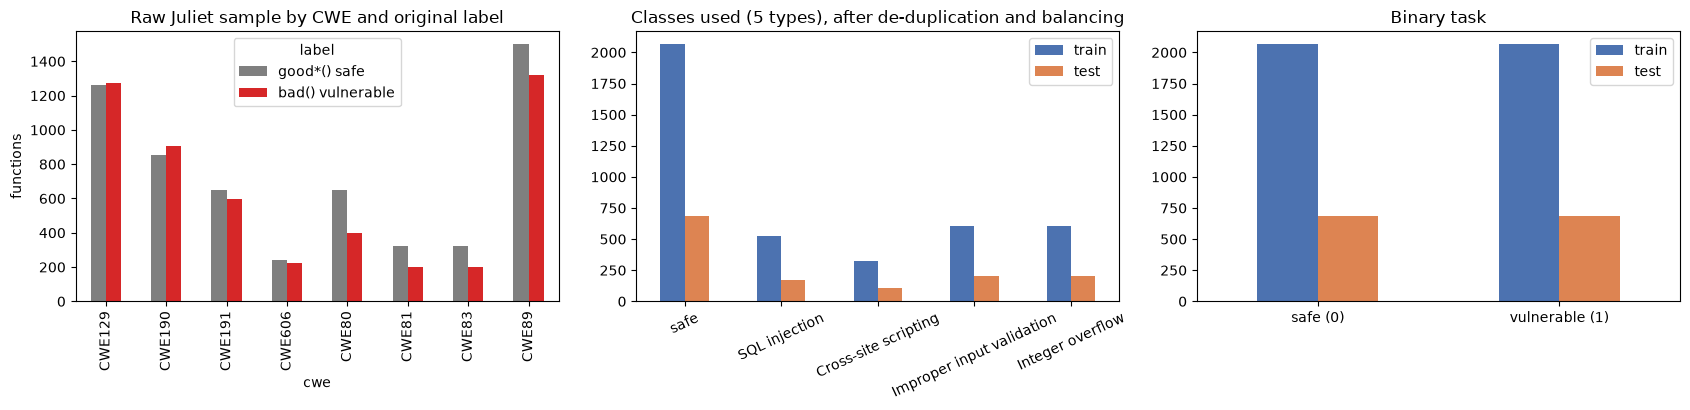

In [12]:
cols = {"safe": "#7f7f7f", "SQL injection": "#d62728", "Cross-site scripting": "#1f77b4", "Improper input validation": "#2ca02c", "Integer overflow": "#ff7f0e"}
fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))
c = raw.groupby(["cwe", "label"]).size().unstack(fill_value=0)
c.rename(columns={0: "good*() safe", 1: "bad() vulnerable"}).plot.bar(ax=ax[0], color=["#7f7f7f", "#d62728"]); ax[0].set_title("Raw Juliet sample by CWE and original label")
ax[0].set_ylabel("functions")
cnt = pd.DataFrame({"train": np.bincount(ytr_5, minlength=5), "test": np.bincount(yte_5, minlength=5)}, index=TYPE_NAMES)
cnt.plot.bar(ax=ax[1], color=["#4c72b0", "#dd8452"]); ax[1].set_title("Classes used (5 types), after de-duplication and balancing"); ax[1].tick_params(axis="x", rotation=25)
bb = pd.DataFrame({"train": np.bincount(ytr_b), "test": np.bincount(yte_b)}, index=["safe (0)", "vulnerable (1)"])
bb.plot.bar(ax=ax[2], color=["#4c72b0", "#dd8452"]); ax[2].set_title("Binary task"); ax[2].tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.show()

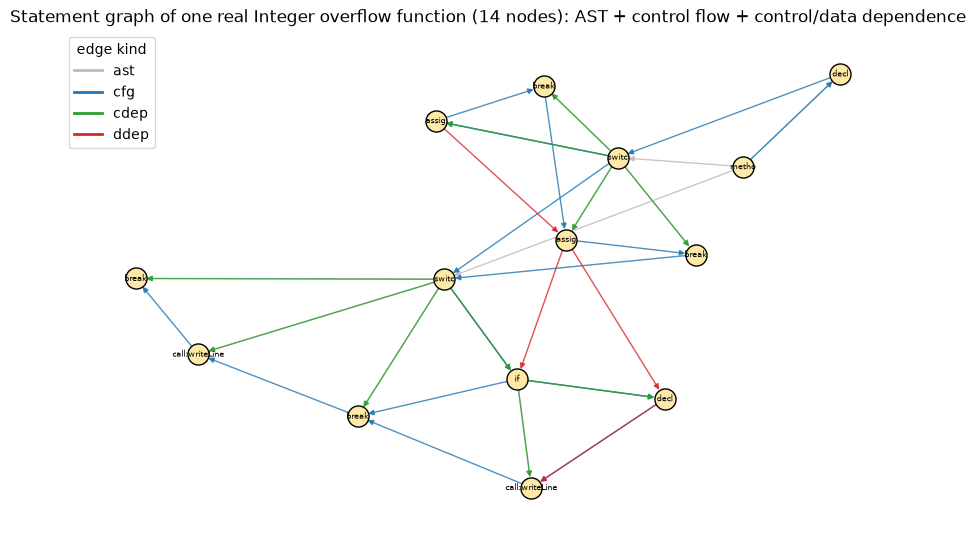

In [13]:
ty, ed = G_tr[i_ex]
g = nx.MultiDiGraph(); g.add_nodes_from(range(len(ty)))
ecol = {"ast": "#bbbbbb", "cfg": "#1f77b4", "cdep": "#2ca02c", "ddep": "#d62728"}
for k, es in ed.items():
    for a, b in es: g.add_edge(a, b, kind=k)
pos = nx.spring_layout(nx.Graph(g), seed=SEED, k=0.6)
fig, ax = plt.subplots(figsize=(11, 6.5))
nx.draw_networkx_nodes(g, pos, node_size=230, node_color="#ffe9a8", edgecolors="k", ax=ax)
nx.draw_networkx_labels(g, pos, {i: t.split("|")[0][:5] + (":" + t.split("|")[1][:9] if "|" in t and t.split("|")[1] else "") for i, t in enumerate(ty)}, font_size=6, ax=ax)
for k, col in ecol.items():
    nx.draw_networkx_edges(g, pos, edgelist=[(a, b) for a, b, d in g.edges(data=True) if d["kind"] == k], edge_color=col, alpha=.8, width=1, arrows=True, arrowsize=8, ax=ax, node_size=230)
ax.legend(handles=[plt.Line2D([0], [0], color=c_, lw=2, label=k) for k, c_ in ecol.items()], loc="upper left", title="edge kind")
ax.set_title(f"Statement graph of one real {ex.family} function ({len(ty)} nodes): AST + control flow + control/data dependence"); ax.axis("off")
plt.show()

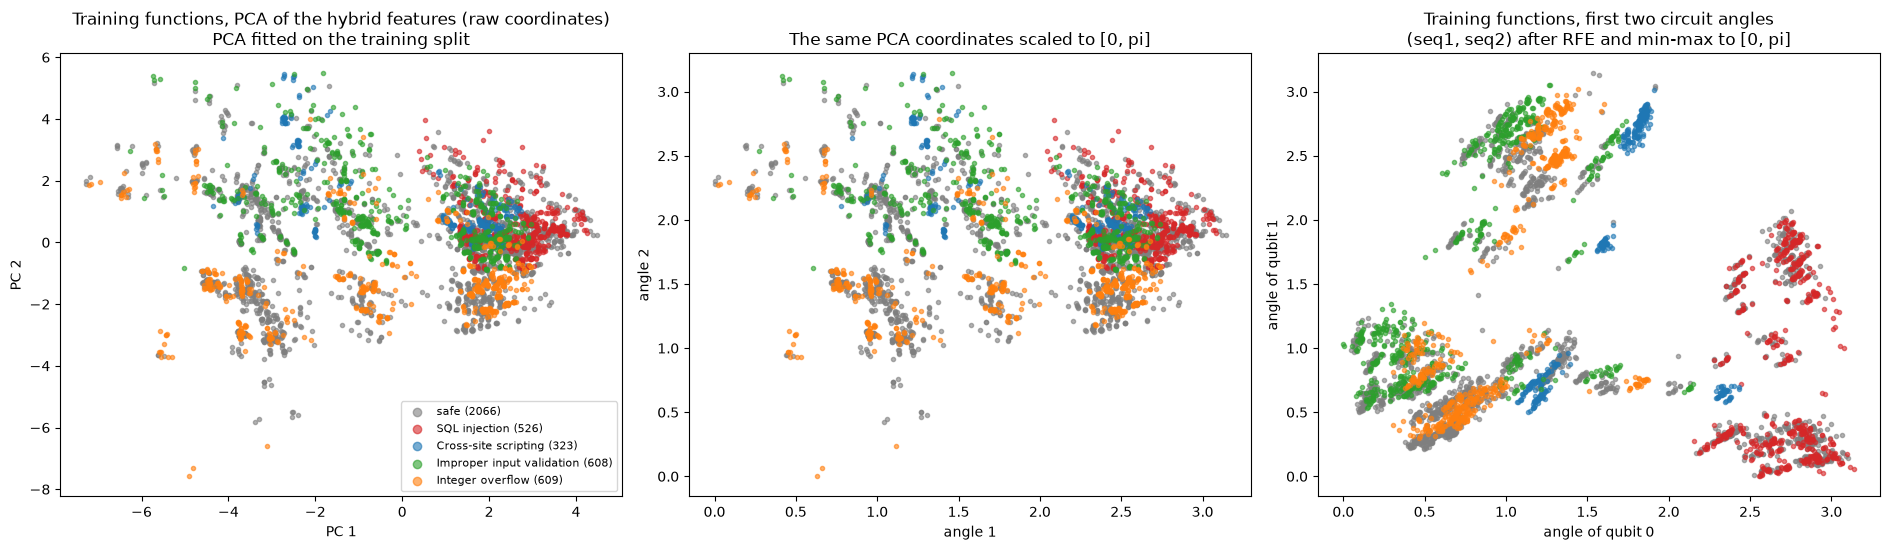

explained variance of the two PCA components: [0.259 0.099]


In [14]:
pca = PCA(2, random_state=SEED).fit(Hz_tr)
P_tr, P_te = pca.transform(Hz_tr), pca.transform(Hz_te)
sc = MinMaxScaler((0, np.pi)).fit(P_tr); S_tr, S_te = sc.transform(P_tr), np.clip(sc.transform(P_te), 0, np.pi)
fig, ax = plt.subplots(1, 3, figsize=(19, 5.6))
for k, nm in enumerate(TYPE_NAMES):
    m_ = ytr_5 == k
    ax[0].scatter(P_tr[m_, 0], P_tr[m_, 1], s=9, alpha=.6, c=cols[nm], label=f"{nm} ({m_.sum()})")
    ax[1].scatter(S_tr[m_, 0], S_tr[m_, 1], s=9, alpha=.6, c=cols[nm])
    ax[2].scatter(Xa_tr[m_, 0], Xa_tr[m_, 1], s=9, alpha=.6, c=cols[nm])
ax[0].set_title("Training functions, PCA of the hybrid features (raw coordinates)\nPCA fitted on the training split"); ax[0].set_xlabel("PC 1"); ax[0].set_ylabel("PC 2")
ax[1].set_title("The same PCA coordinates scaled to [0, pi]"); ax[1].set_xlabel("angle 1"); ax[1].set_ylabel("angle 2")
ax[2].set_title(f"Training functions, first two circuit angles\n({names_q[0]}, {names_q[1]}) after RFE and min-max to [0, pi]"); ax[2].set_xlabel("angle of qubit 0"); ax[2].set_ylabel("angle of qubit 1")
ax[0].legend(fontsize=8, markerscale=2)
plt.tight_layout(); plt.show()
print(f"explained variance of the two PCA components: {pca.explained_variance_ratio_.round(3)}")

**Reading the plots.** Safe and vulnerable functions overlap strongly in the first two principal components: what separates them is mostly a *relation* (is the sink fed by
untrusted data, is there a bound check) that a handful of global statistics only partly capture. This is why a tree model on the eight selected features does much better than
smooth models such as the RBF-SVC, and it predicts how the circuit will behave: its input is a smooth function of eight numbers.

## 3. Classical baselines on exactly the same inputs

Random forest (200 trees), RBF-SVC (C = 1, no tuning) and, with the paper's optimiser settings (SGD, learning rate 0.005, momentum 0.9, dropout 0.3, cross-entropy), a Keras MLP, a 1-D CNN and an LSTM
that reads the features as a sequence. They are trained on five inputs: the eight features of the circuit (continuous and as bits), the full 28-dimensional hybrid vector, and the two branches alone (which
also tests the paper's "hybrid features help" claim). Hyper-parameters are fixed in advance; nothing is tuned on the test split.

In [15]:
def bin_metrics(y, pred):
    """Vulnerable = positive class."""
    return dict(acc=accuracy_score(y, pred), precision=precision_score(y, pred, zero_division=0),
                recall=recall_score(y, pred, zero_division=0), f1=f1_score(y, pred, zero_division=0))

def multi_metrics(y, pred):
    return dict(acc=accuracy_score(y, pred), macro_f1=f1_score(y, pred, average="macro", zero_division=0))

results = []          # one dict per (model, input set, seed)
def log_result(task, model, inputs, seed, y, pred, secs):
    m = bin_metrics(y, pred) if task == "binary" else multi_metrics(y, pred)
    results.append(dict(task=task, model=model, inputs=inputs, seed=seed, secs=secs, **m))
    return m

INPUT_SETS = {                                    # name -> (train matrix, test matrix)
    f"{N_QUBITS} selected (continuous)": (Xq_tr, Xq_te),
    f"{N_QUBITS} bits (basis input)":    (Xb_tr, Xb_te),
    f"hybrid {H_tr.shape[1]} (seq+graph)": (Hz_tr, Hz_te),
    f"sequence only {Zs_tr.shape[1]}":    (StandardScaler().fit(Zs_tr).transform(Zs_tr), StandardScaler().fit(Zs_tr).transform(Zs_te)),
    f"graph only {Gs_tr.shape[1]}":       (StandardScaler().fit(Gs_tr).transform(Gs_tr), StandardScaler().fit(Gs_tr).transform(Gs_te)),
}

In [16]:
for iname, (A, B) in INPUT_SETS.items():
    for task, ytr, yte in [("binary", ytr_b, yte_b), ("types", ytr_5, yte_5)]:
        for seed in BASE_SEEDS:
            for mname, mk in [("RandomForest", lambda s: RandomForestClassifier(200, random_state=s, n_jobs=1)),
                              ("SVC (rbf, C=1)", lambda s: SVC(kernel="rbf", C=1.0, random_state=s))]:
                if mname.startswith("SVC") and seed != BASE_SEEDS[0]: continue          # deterministic
                t0 = time.time(); mdl = mk(seed).fit(A, ytr); pr = mdl.predict(B)
                log_result(task, mname, iname, seed, yte, pr, time.time() - t0)
res = pd.DataFrame(results)
show = res[res.task == "binary"].groupby(["inputs", "model"])[["acc", "precision", "recall", "f1", "secs"]].agg(["mean"]).round(3)
show.columns = [c[0] for c in show.columns]
show

acc  precision  recall     f1   secs
inputs                  model                                                 
8 bits (basis input)    RandomForest    0.695      0.685   0.722  0.703  1.198
                        SVC (rbf, C=1)  0.686      0.679   0.704  0.691  1.707
8 selected (continuous) RandomForest    0.941      0.937   0.945  0.941  3.386
                        SVC (rbf, C=1)  0.759      0.782   0.718  0.749  2.503
graph only 12           RandomForest    0.867      0.868   0.866  0.867  4.671
                        SVC (rbf, C=1)  0.738      0.744   0.726  0.735  3.135
hybrid 28 (seq+graph)   RandomForest    0.940      0.935   0.945  0.940  5.848
                        SVC (rbf, C=1)  0.851      0.855   0.845  0.850  2.622
sequence only 16        RandomForest    0.930      0.927   0.933  0.930  5.194
                        SVC (rbf, C=1)  0.837      0.840   0.833  0.837  1.913

In [17]:
import tensorflow as tf
from tensorflow import keras
tf.get_logger().setLevel("ERROR")

def make_keras(kind, n_in, n_out, seed):
    keras.utils.set_random_seed(seed)
    inp = keras.Input((n_in,))
    if kind == "MLP (Keras)":
        x = keras.layers.Dense(128, activation="relu")(inp); x = keras.layers.Dropout(0.3)(x)
    elif kind == "CNN (Keras)":
        x = keras.layers.Reshape((n_in, 1))(inp)
        x = keras.layers.Conv1D(16, 3, padding="same", activation="relu")(x)
        x = keras.layers.Conv1D(16, 3, padding="same", activation="relu")(x)
        x = keras.layers.GlobalMaxPooling1D()(x); x = keras.layers.Dense(32, activation="relu")(x); x = keras.layers.Dropout(0.3)(x)
    else:                                                                         # LSTM over the feature sequence
        x = keras.layers.Reshape((n_in, 1))(inp); x = keras.layers.LSTM(32)(x); x = keras.layers.Dropout(0.3)(x)
    out = keras.layers.Dense(n_out, activation="softmax")(x)
    mdl = keras.Model(inp, out)
    # paper, "Experimental setup": learning rate 0.005, momentum 0.9, dropout 0.3, cross-entropy
    mdl.compile(optimizer=keras.optimizers.SGD(0.005, momentum=0.9), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return mdl

for iname in [f"{N_QUBITS} selected (continuous)", f"hybrid {H_tr.shape[1]} (seq+graph)"]:
    A, B = INPUT_SETS[iname]
    for task, ytr, yte, k in [("binary", ytr_b, yte_b, 2), ("types", ytr_5, yte_5, 5)]:
        for kind in ["MLP (Keras)", "CNN (Keras)", "LSTM (Keras)"]:
            for seed in KERAS_SEEDS:
                t0 = time.time(); mdl = make_keras(kind, A.shape[1], k, seed)
                mdl.fit(A, ytr, epochs=KERAS_EPOCHS, batch_size=KERAS_BATCH, verbose=0)
                pr = mdl.predict(B, verbose=0).argmax(1)
                log_result(task, kind, iname, seed, yte, pr, time.time() - t0)
        print("done", iname, task, flush=True)
res = pd.DataFrame(results)

done 8 selected (continuous) binary


done 8 selected (continuous) types


done hybrid 28 (seq+graph) binary


done hybrid 28 (seq+graph) types


## 4. The quantum model: QCNN with self-attentive pooling

The paper describes the layers in words (Fig. 7); the exact gates are not given, so the circuit below is our reading (every gate choice is marked `# CHOICE:` in the code).

1. **Encoding.** *Basis*: bit $b_i$ -> $|b_i\rangle$ on qubit $i$ (the paper). *Angle*: $R_Y(x_i)$ with $x_i\in[0,\pi]$ (the paper also says the RY gate converts the code into qubits).
2. **Convolution layer.** The same 6-parameter two-qubit filter ($R_Y R_Y$, CNOT, $R_Z R_Z$, CNOT, $R_Y R_Y$) acts on neighbouring pairs of the still-active qubits, then on the shifted pairs
   (weights shared inside a layer, as in a convolution).
3. **Self-attentive pooling.** After the first convolution layer, $\langle Z_i\rangle$ of every qubit is measured; these eight numbers are the *tokens*. A classical **multi-head self-attention** layer (2 heads, token
   width 4, learned positional embedding, residual connection) mixes the tokens, and a **sigmoid** turns each output into a gate $s_i\in(0,1)$ (the "spatial channel restoration + sigmoid" of the paper).
   Pooling then discards qubit $i$ with controlled rotations $CRZ(\phi_1 s_i)$, $X$, $CRX(\phi_2 s_i)$, $X$ onto its neighbour: **the attention gate decides how strongly the qubit that is thrown away passes its information on.**
4. **Repeat** convolution and pooling (8 -> 4 -> 2 -> 1 qubits for the binary task) and read $\langle Z_0\rangle$ after a final trainable $R_Y R_Z$; the class probability is $(1-\langle Z_0\rangle)/2$.
   For the 5-class task the circuit pools once (8 -> 4), applies a final convolution and uses the probabilities of the four remaining wires; the first five of the 16 outcomes are the classes.
5. **Training.** Cross-entropy on the circuit's probabilities, Adam, exact simulation with back-propagation through `default.qubit` (no shot noise).

The attention weights are classical parameters of the model; the notebook reports them separately from the quantum parameters. Because the paper trains on SARD with a four-qubit device and gives no
circuit, nothing below claims to be the authors' circuit.

In [18]:
import pennylane as qml
import autograd.numpy as anp
from autograd import value_and_grad

def schedule(n, stages):
    """Active wires, convolution pairs and (discarded, kept) pooling pairs of every QCNN stage."""
    act, out = list(range(n)), []
    for _ in range(stages):
        pairs = [(act[i], act[i + 1]) for i in range(0, len(act) - 1, 2)] + [(act[i], act[i + 1]) for i in range(1, len(act) - 1, 2)]
        out.append((list(act), pairs, list(zip(act[1::2], act[0::2]))))
        act = act[0::2]
    return out, act

def conv_pairs(act):
    return [(act[i], act[i + 1]) for i in range(0, len(act) - 1, 2)] + [(act[i], act[i + 1]) for i in range(1, len(act) - 1, 2)]

def encode(x, n, encoding):
    if encoding == "angle":                       # RY(x_i) with x_i in [0, pi]  (the paper: "the RY gate converts the code into qubits")
        for i in range(n): qml.RY(x[..., i], wires=i)
    elif encoding == "basis":                     # batched basis embedding: RX(pi*b) = -i X^b, i.e. |b> up to a global phase
        for i in range(n): qml.RX(np.pi * x[..., i], wires=i)
    elif encoding == "basis_exact":               # the PennyLane operation itself (single sample only); used for drawing and the equivalence test
        qml.BasisEmbedding(np.asarray(x).astype(int), wires=range(n))

def conv_block(w, a, b):                          # CHOICE: 6-parameter two-qubit convolution filter, weights shared inside a layer
    qml.RY(w[0], wires=a); qml.RY(w[1], wires=b); qml.CNOT(wires=[a, b])
    qml.RZ(w[2], wires=a); qml.RZ(w[3], wires=b); qml.CNOT(wires=[b, a])
    qml.RY(w[4], wires=a); qml.RY(w[5], wires=b)

def pool_block(w, gate, src, dst):                # CHOICE: controlled rotations from the discarded qubit; the attention gate scales them
    qml.CRZ(w[0] * gate, wires=[src, dst]); qml.PauliX(wires=src); qml.CRX(w[1] * gate, wires=[src, dst]); qml.PauliX(wires=src)

class SAQCNN:
    """Quantum convolutional network with self-attentive pooling.
    1. encode the features, 2. first convolution layer, 3. read <Z_i> of every qubit = one 'token' per qubit,
    4. multi-head self-attention over the tokens -> one gate s_i in (0,1) per qubit, 5. full circuit in which the pooling
    rotation that discards qubit i is multiplied by s_i, 6. read-out (<Z> of one qubit, or the probabilities of the last wires)."""
    def __init__(self, n, stages, task, n_classes, encoding, d_att=4, heads=2, final_conv=False, seed=42):
        self.n, self.stages, self.task, self.K, self.encoding = n, stages, task, n_classes, encoding
        self.D, self.H, self.final_conv = d_att, heads, final_conv
        self.sched, self.last = schedule(n, stages)
        self.dev = qml.device("default.qubit", wires=n)
        D = d_att
        self.shapes = dict(conv=(stages, 6), pool=(stages, 2), fconv=(6,), fin=(2,), Win=(D,), E=(n, D), Wq=(D, D), Wk=(D, D),
                           Wv=(D, D), Wo=(D, D), wg=(D,), bg=(1,))
        self.sizes = {k: int(np.prod(v)) for k, v in self.shapes.items()}
        self.n_params = sum(self.sizes.values())
        self.n_quantum = self.sizes["conv"] + self.sizes["pool"] + (self.sizes["fconv"] if final_conv else 0) + (self.sizes["fin"] if task == "binary" else 0)
        r = np.random.default_rng(seed)
        th = np.concatenate([r.uniform(0, 2 * np.pi, self.sizes[k]) if k in ("conv", "pool", "fconv", "fin") else r.normal(0, 0.5, self.sizes[k])
                             for k in self.shapes])
        self.theta0 = th
        self._set_bias(th)
        self._build()
    def _set_bias(self, th):
        i = sum(self.sizes[k] for k in list(self.shapes)[:-1]); th[i] = 1.0          # gates start near sigmoid(1) = 0.73
    def unpack(self, th):
        out, i = {}, 0
        for k, shp in self.shapes.items():
            out[k] = th[i:i + self.sizes[k]].reshape(shp); i += self.sizes[k]
        return out
    # ---- quantum circuits
    def _build(self):
        n, enc = self.n, self.encoding
        @qml.qnode(self.dev, interface="autograd", diff_method="backprop")
        def tokens(x, conv0):                                         # circuit A: encoding + first convolution layer
            encode(x, n, enc)
            for a, b in self.sched[0][1]: conv_block(conv0, a, b)
            return [qml.expval(qml.PauliZ(i)) for i in range(n)]
        @qml.qnode(self.dev, interface="autograd", diff_method="backprop")
        def full(x, conv, pool, fconv, fin, gates):                   # circuit B: the whole attentive QCNN
            encode(x, n, enc)
            for st, (act, pairs, pools) in enumerate(self.sched):
                for a, b in pairs: conv_block(conv[st], a, b)
                for src, dst in pools: pool_block(pool[st], gates[..., src], src, dst)
            if self.final_conv:
                for a, b in conv_pairs(self.last): conv_block(fconv, a, b)
            if self.task == "binary":
                qml.RY(fin[0], wires=self.last[0]); qml.RZ(fin[1], wires=self.last[0])
                return qml.expval(qml.PauliZ(self.last[0]))
            return qml.probs(wires=self.last)
        self.tokens, self.full = tokens, full
    # ---- classical self-attention on the qubit tokens
    def attention(self, p, z):
        B = z.shape[0]; D, H = self.D, self.H; dk = D // H
        x = z[:, :, None] * p["Win"][None, None, :] + p["E"][None]
        Q, Kk, V = anp.matmul(x, p["Wq"]), anp.matmul(x, p["Wk"]), anp.matmul(x, p["Wv"])
        outs = []
        for h in range(H):
            sl = slice(h * dk, (h + 1) * dk)
            sc = anp.matmul(Q[:, :, sl], anp.swapaxes(Kk[:, :, sl], 1, 2)) / np.sqrt(dk)
            e = anp.exp(sc - anp.max(sc, axis=-1, keepdims=True)); A = e / anp.sum(e, axis=-1, keepdims=True)
            outs.append(anp.matmul(A, V[:, :, sl]))
        O = anp.matmul(anp.concatenate(outs, axis=-1), p["Wo"]) + x                 # residual connection
        return 1.0 / (1.0 + anp.exp(-(anp.matmul(O, p["wg"]) + p["bg"][0])))        # (B, n) gates in (0, 1)
    def forward(self, th, X, use_attention=True):
        p = self.unpack(th)
        if use_attention:
            z = anp.stack(self.tokens(X, p["conv"][0]), axis=1)
            gates = self.attention(p, z)
        else:
            gates = anp.ones((X.shape[0], self.n))
        return self.full(X, p["conv"], p["pool"], p["fconv"], p["fin"], gates), gates
    def proba(self, th, X, use_attention=True):
        out, _ = self.forward(th, X, use_attention)
        if self.task == "binary":
            p1 = anp.clip((1 - out) / 2, 1e-6, 1 - 1e-6); return anp.stack([1 - p1, p1], axis=1)
        pk = out[:, :self.K] + 1e-9; return pk / anp.sum(pk, axis=1, keepdims=True)
    def loss(self, th, X, y, use_attention=True):
        P = self.proba(th, X, use_attention)
        return -anp.mean(anp.log(P[anp.arange(len(y)), y]))
    def fit(self, X, y, epochs, batch, lr, seed, use_attention=True, log=None, th0=None):
        r = np.random.default_rng(seed)
        th = (self.theta0.copy() if th0 is None else th0.copy())
        m, v, t = np.zeros_like(th), np.zeros_like(th), 0
        vg = value_and_grad(lambda t_, xb, yb: self.loss(t_, xb, yb, use_attention))
        hist = []
        for ep in range(epochs):
            perm = r.permutation(len(X)); ls = []
            for i in range(0, len(X), batch):
                idx = perm[i:i + batch]
                l, g = vg(th, X[idx], y[idx]); t += 1
                m = 0.9 * m + 0.1 * g; v = 0.999 * v + 0.001 * g * g
                th = th - lr * (m / (1 - 0.9 ** t)) / (np.sqrt(v / (1 - 0.999 ** t)) + 1e-8); ls.append(float(l))
            hist.append(float(np.mean(ls)))
            if log: log(ep, hist[-1])
        self.theta = th; return hist
    def predict(self, X, th=None, use_attention=True, chunk=256):
        th = self.theta if th is None else th
        P = np.vstack([np.asarray(self.proba(th, X[i:i + chunk], use_attention)) for i in range(0, len(X), chunk)])
        return P.argmax(1), P

## Quantum Circuit Architecture

Three architectures are trained: the binary model with **angle** encoding, the binary model with **basis** encoding, and the **5-class** model; circuit A (encoding + first convolution) is the
sub-circuit that produces the attention tokens. The drawings below come from the `QNode`s that are executed in the experiments (`qml.draw_mpl`); the values printed on the gates are the *initial*
parameters of the seed-42 model and the attention gates computed for the first training function. The basis-encoding circuit is drawn with `qml.BasisEmbedding`; for batched training the same
encoding is written as $R_X(\pi b_i) = -iX^{b_i}$, which equals the basis state up to a global phase, and the exactness check after training asserts that both give the same output.
Qubit count, depth, gate count and parameter counts are printed first.

In [19]:
# The three distinct architectures: binary QCNN-SAP with angle encoding (RY), the same circuit with the paper's basis encoding,
# and the 5-class variant (one pooling stage, final convolution, probability read-out on four wires).
m_bin = SAQCNN(N_QUBITS, 3, "binary", 2, "angle", seed=SEED)
m_bas = SAQCNN(N_QUBITS, 3, "binary", 2, "basis_exact", seed=SEED)       # drawn with qml.BasisEmbedding; trained as RX(pi*b), see the exactness check
m_typ = SAQCNN(N_QUBITS, 1, "multi", len(TYPE_NAMES), "angle", final_conv=True, seed=SEED)

def tape_of(qnode, args):
    tapes, _ = qml.workflow.construct_batch(qnode, level="device")(*args)
    return tapes[0]
def describe(name, mdl, x):
    a = circuit_args(mdl, x)
    tp = tape_of(mdl.full, a)
    print(f"{name:34s} qubits {N_QUBITS} | depth {tp.graph.get_depth():3d} | gates {len(tp.operations):3d} | "
          f"quantum trainable parameters {mdl.n_quantum:3d} | classical self-attention parameters {mdl.n_params - mdl.n_quantum:3d}")
    return a

def circuit_args(mdl, x, th=None):
    th = mdl.theta0 if th is None else th
    p = mdl.unpack(th)
    z = np.array(mdl.tokens(x, p["conv"][0])); gates = np.array(mdl.attention(p, z[None, :]))[0]
    return (x, p["conv"], p["pool"], p["fconv"], p["fin"], gates)

args_bin = describe("B: binary, angle encoding", m_bin, Xa_tr[0])
args_bas = describe("B: binary, basis encoding", m_bas, Xb_tr[0])
args_typ = describe("B: 5 classes, angle encoding", m_typ, Xa_tr[0])
tpA = tape_of(m_bin.tokens, (Xa_tr[0], m_bin.unpack(m_bin.theta0)["conv"][0]))
print(f"{'A: tokens (encoding + conv layer 1)':34s} qubits {N_QUBITS} | depth {tpA.graph.get_depth():3d} | gates {len(tpA.operations):3d} | "
      f"parameters {m_bin.sizes['conv'] // m_bin.stages}")

B: binary, angle encoding          qubits 8 | depth  37 | gates 126 | quantum trainable parameters  26 | classical self-attention parameters 111
B: binary, basis encoding          qubits 8 | depth  37 | gates 119 | quantum trainable parameters  26 | classical self-attention parameters 111
B: 5 classes, angle encoding       qubits 8 | depth  24 | gates 104 | quantum trainable parameters  14 | classical self-attention parameters 107
A: tokens (encoding + conv layer 1) qubits 8 | depth  11 | gates  64 | parameters 6


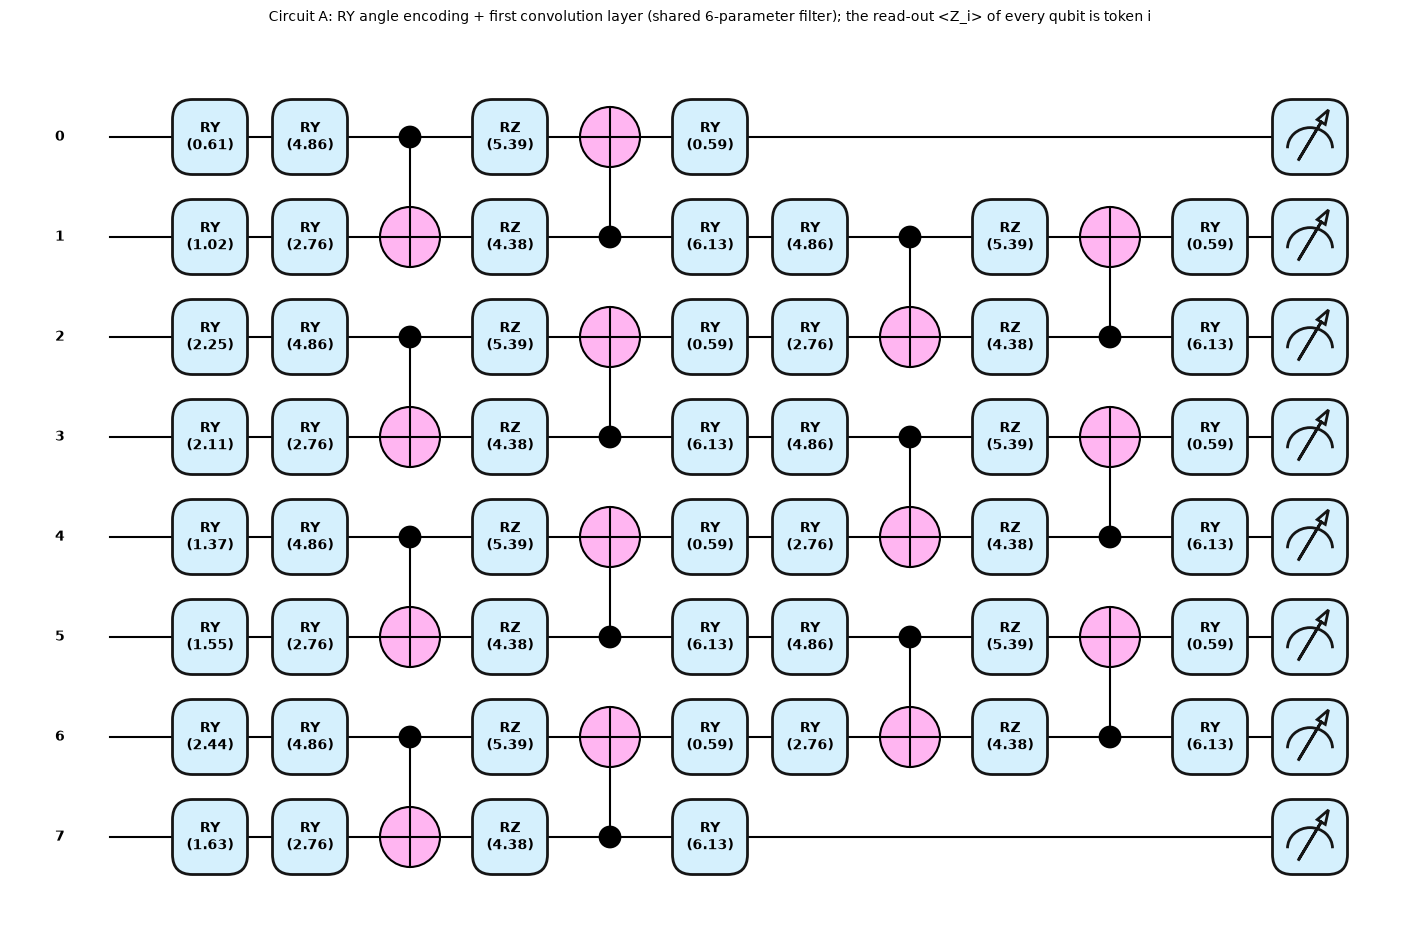

In [20]:
fig, ax = qml.draw_mpl(m_bin.tokens, decimals=2, style="pennylane", fontsize=10)(Xa_tr[0], m_bin.unpack(m_bin.theta0)["conv"][0])
fig.suptitle("Circuit A: RY angle encoding + first convolution layer (shared 6-parameter filter); the read-out <Z_i> of every qubit is token i", y=1.03, fontsize=10)
plt.show()

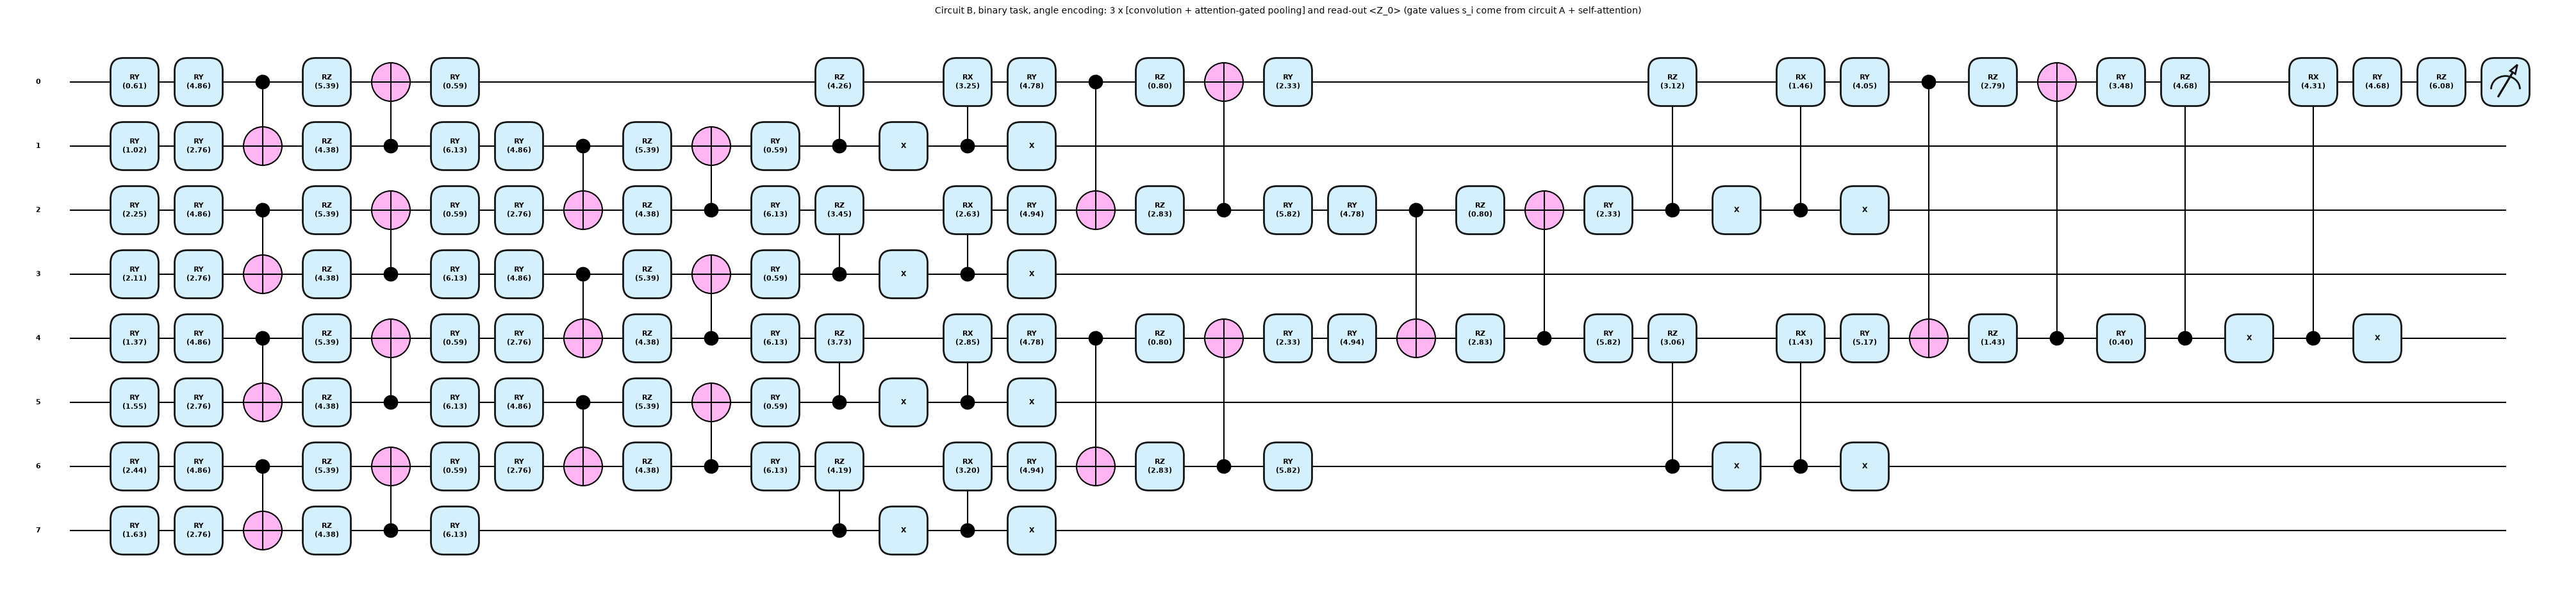

In [21]:
fig, ax = qml.draw_mpl(m_bin.full, decimals=2, style="pennylane", fontsize=8)(*args_bin)
fig.suptitle("Circuit B, binary task, angle encoding: 3 x [convolution + attention-gated pooling] and read-out <Z_0> (gate values s_i come from circuit A + self-attention)", y=1.02, fontsize=10)
plt.show()

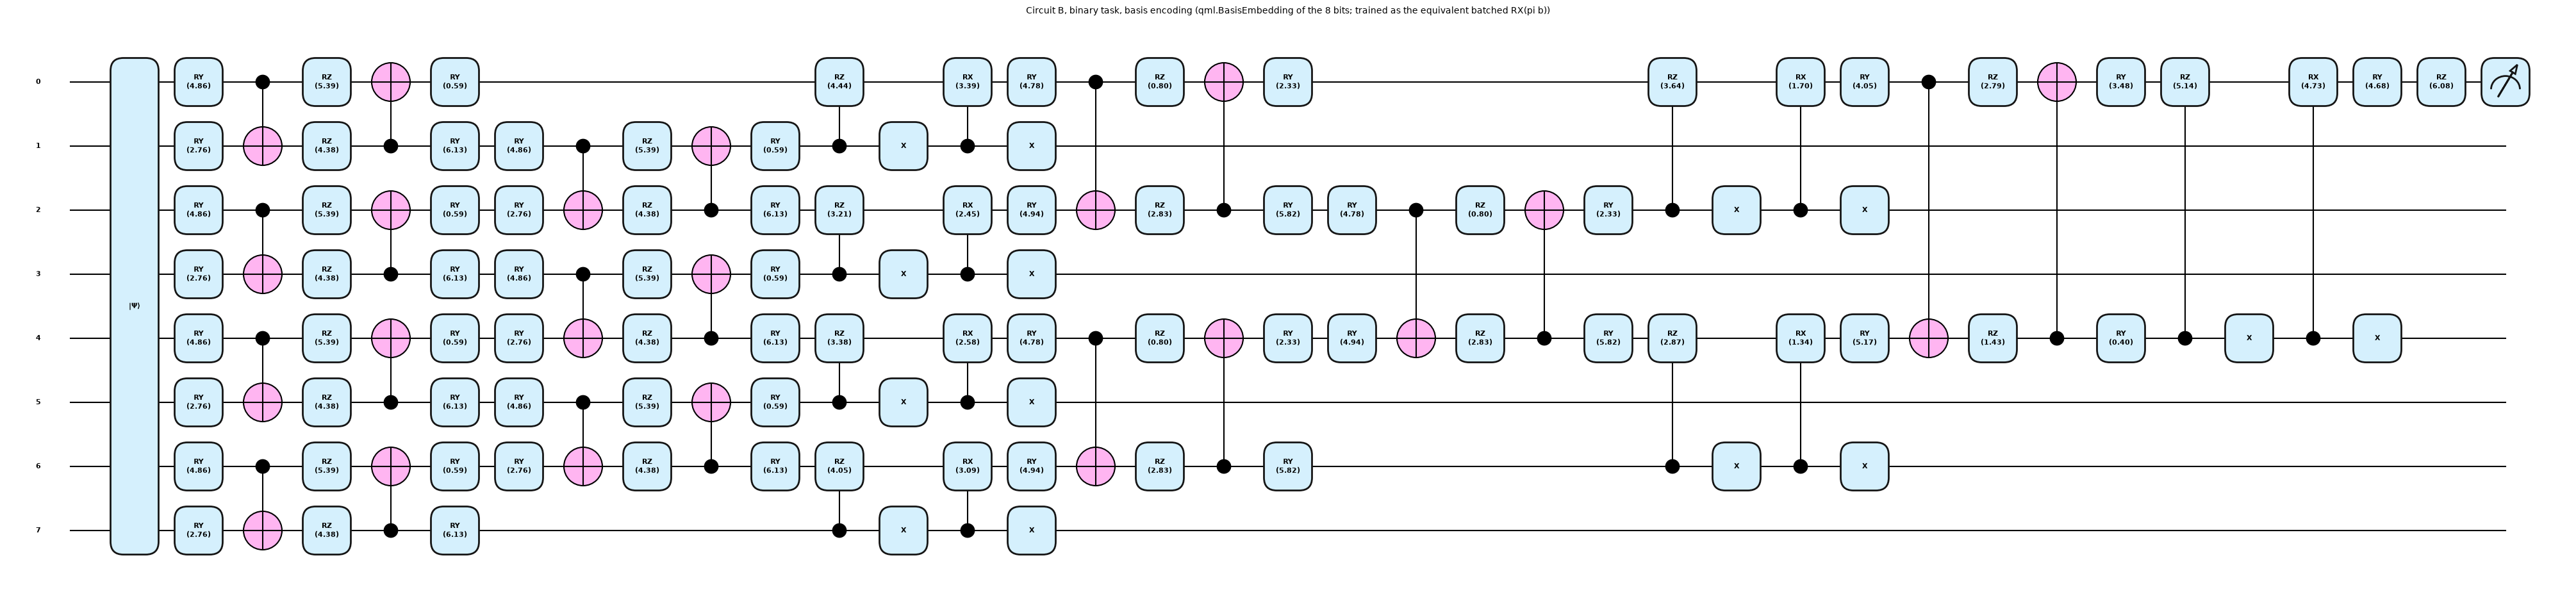

In [22]:
fig, ax = qml.draw_mpl(m_bas.full, decimals=2, style="pennylane", fontsize=8)(*args_bas)
fig.suptitle("Circuit B, binary task, basis encoding (qml.BasisEmbedding of the 8 bits; trained as the equivalent batched RX(pi b))", y=1.02, fontsize=10)
plt.show()

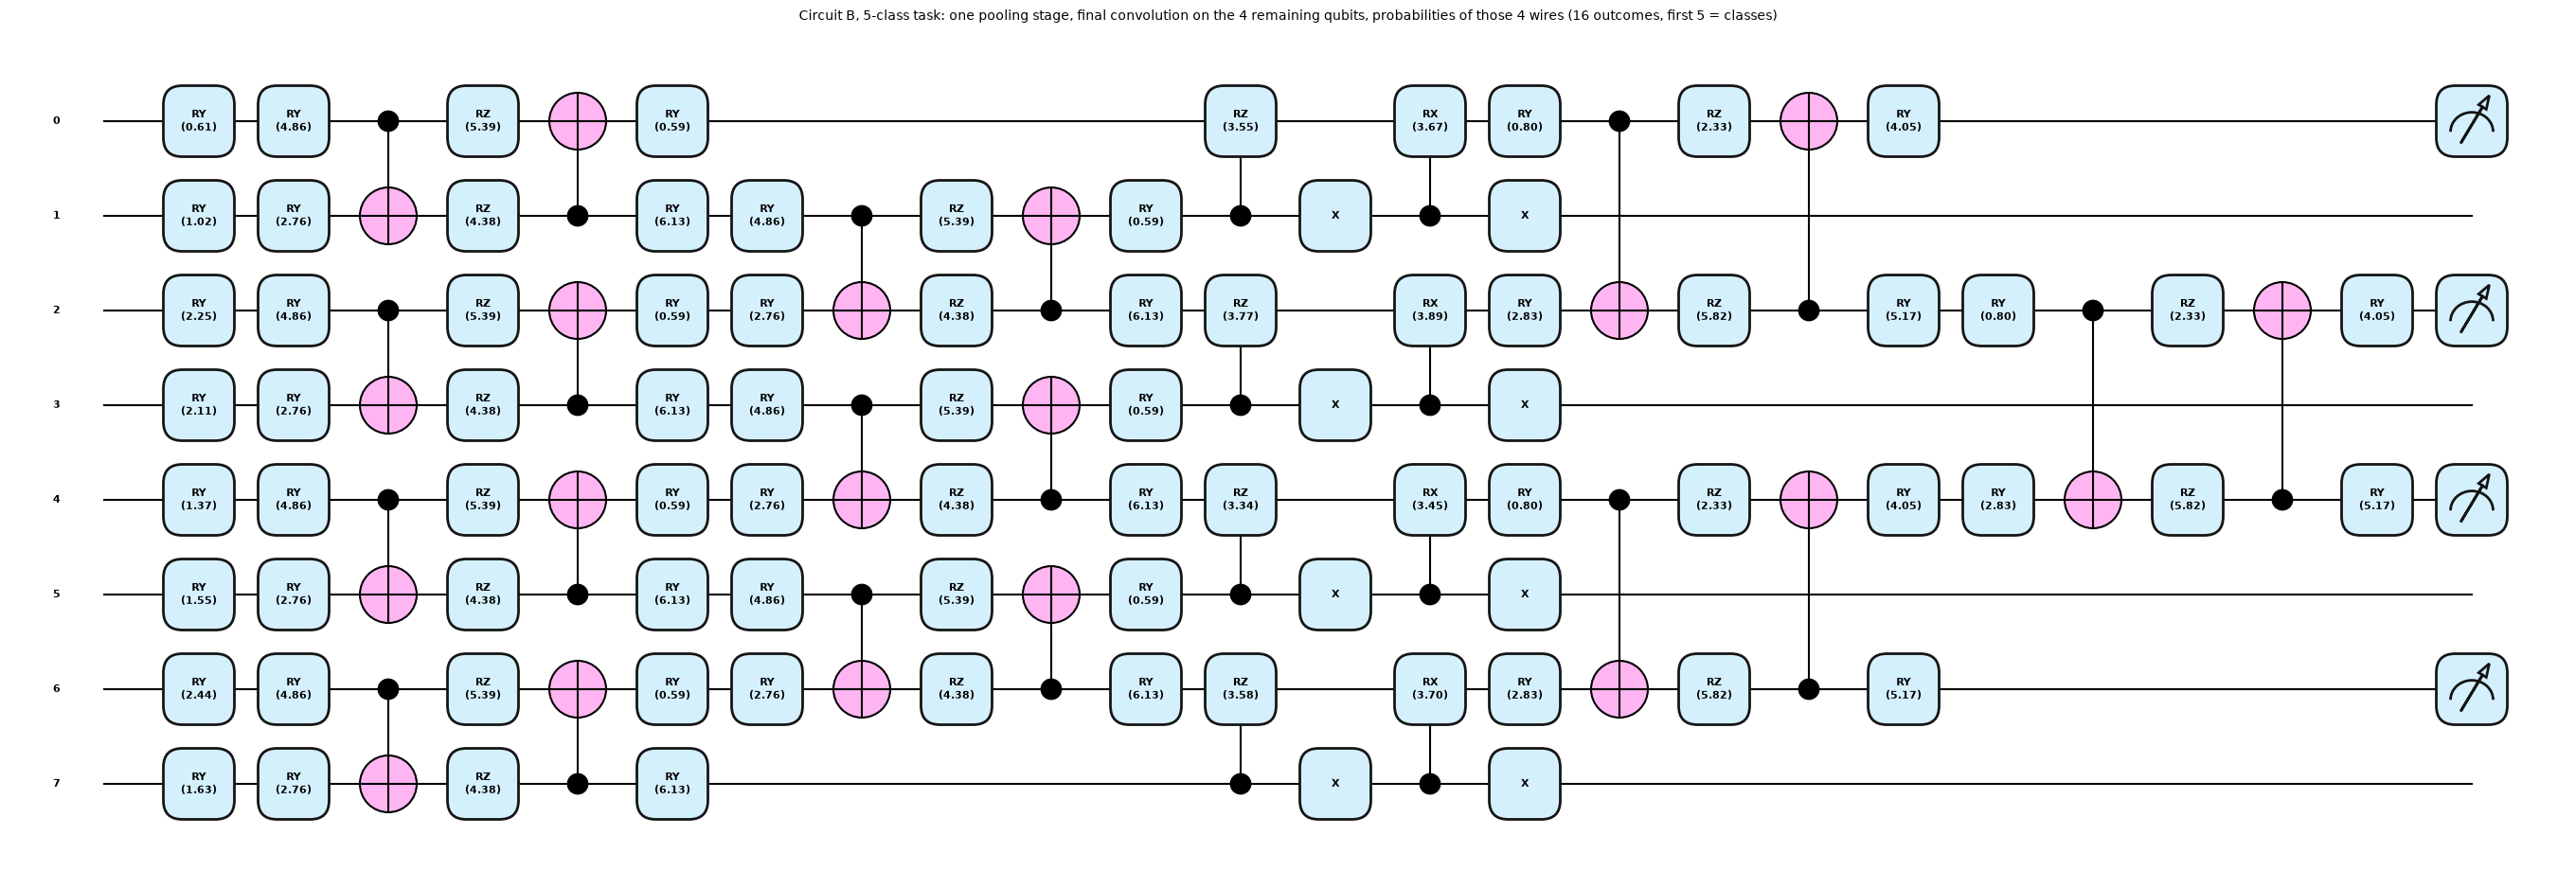

In [23]:
fig, ax = qml.draw_mpl(m_typ.full, decimals=2, style="pennylane", fontsize=8)(*args_typ)
fig.suptitle("Circuit B, 5-class task: one pooling stage, final convolution on the 4 remaining qubits, probabilities of those 4 wires (16 outcomes, first 5 = classes)", y=1.02, fontsize=10)
plt.show()

**Circuit notes.** Circuit A reads out ⟨Z_i⟩ of all eight qubits after one convolution layer: this is where classical and quantum parts meet. In circuit B each `CRZ`/`CRX` pair belongs to a pooling block and its angle is
(learned weight) x (attention gate of the discarded qubit); a discarded qubit is not touched again. The two binary circuits have the same depth; only the encoding layer differs. The 5-class circuit is
shallower (one pooling stage) but reads sixteen outcomes. Assumptions that the paper does not settle: the filter, the neighbour pairing, the pooling gate, the number of stages, the token definition and
the number of qubits.

## 5. Training the quantum models

Training uses a class-balanced subset of the training split (the simulation is the slow part) and the full test split. For every seed: binary basis encoding, binary angle encoding, the binary angle-encoding
circuit **without** the attention gates (all gates fixed to 1: an ablation the paper does not report), and the 5-class circuit. The model after the last epoch is evaluated; nothing is selected on the test split.

In [24]:
# Quantum simulation is the slow part, so the circuit sees a class-balanced subset of the training split (all of the test split).
def balanced_subset(y5, n, seed):
    """n/2 safe functions + n/8 of each of the four vulnerability families (fewer if a family is smaller)."""
    r = np.random.default_rng(seed); idx = []
    for c in range(len(TYPE_NAMES)):
        want = n // 2 if c == 0 else n // 8
        idx += list(r.permutation(np.nonzero(y5 == c)[0])[:want])
    return np.array(sorted(idx))
q_idx = balanced_subset(ytr_5, QUANTUM_TRAIN, SEED)
print(f"quantum training subset: {len(q_idx)} functions {dict(zip(TYPE_NAMES, np.bincount(ytr_5[q_idx], minlength=5)))}")
Q = dict(angle=(Xa_tr[q_idx], Xa_te), basis=(Xb_tr[q_idx], Xb_te))

quantum training subset: 400 functions {'safe': np.int64(200), 'SQL injection': np.int64(50), 'Cross-site scripting': np.int64(50), 'Improper input validation': np.int64(50), 'Integer overflow': np.int64(50)}


In [25]:
q_hist, q_models = {}, {}
def run_q(label, enc, task, seed, use_att=True):
    Xtr_, Xte_ = Q[enc]
    if task == "binary":
        mdl = SAQCNN(N_QUBITS, 3, "binary", 2, enc, seed=seed); ytr_, yte_ = ytr_b[q_idx], yte_b
    else:
        mdl = SAQCNN(N_QUBITS, 1, "multi", len(TYPE_NAMES), enc, final_conv=True, seed=seed); ytr_, yte_ = ytr_5[q_idx], yte_5
    t0 = time.time()
    hist = mdl.fit(Xtr_, ytr_, epochs=EPOCHS_Q, batch=BATCH_Q, lr=LR_Q, seed=seed, use_attention=use_att)
    pr, P = mdl.predict(Xte_, use_attention=use_att)
    secs = time.time() - t0
    m = log_result("binary" if task == "binary" else "types", label, f"{N_QUBITS} qubits, {enc} encoding", seed, yte_, pr, secs)
    q_hist[(label, task, seed)] = hist; q_models[(label, task, seed)] = (mdl, use_att)
    print(f"{label:34s} {task:6s} seed {seed}: " + "  ".join(f"{k} {v:.3f}" for k, v in m.items()) + f"   loss {hist[0]:.3f}->{hist[-1]:.3f}  ({secs:.0f} s)", flush=True)
    return mdl

for seed in Q_SEEDS:
    run_q("QCNN-SAP basis encoding", "basis", "binary", seed)
    run_q("QCNN-SAP angle encoding", "angle", "binary", seed)
    run_q("QCNN (no attention) angle", "angle", "binary", seed, use_att=False)
    run_q("QCNN-SAP angle encoding", "angle", "types", seed)
res = pd.DataFrame(results)

QCNN-SAP basis encoding            binary seed 42: acc 0.610  precision 0.594  recall 0.694  f1 0.640   loss 0.684->0.604  (232 s)


QCNN-SAP angle encoding            binary seed 42: acc 0.671  precision 0.697  recall 0.604  f1 0.647   loss 0.664->0.578  (257 s)


QCNN (no attention) angle          binary seed 42: acc 0.621  precision 0.621  recall 0.623  f1 0.622   loss 0.672->0.601  (175 s)


QCNN-SAP angle encoding            types  seed 42: acc 0.576  macro_f1 0.491   loss 1.542->1.051  (237 s)


QCNN-SAP basis encoding            binary seed 43: acc 0.655  precision 0.682  recall 0.582  f1 0.628   loss 0.684->0.560  (250 s)


QCNN-SAP angle encoding            binary seed 43: acc 0.678  precision 0.721  recall 0.581  f1 0.643   loss 0.685->0.547  (227 s)


QCNN (no attention) angle          binary seed 43: acc 0.663  precision 0.677  recall 0.623  f1 0.649   loss 0.703->0.587  (152 s)


QCNN-SAP angle encoding            types  seed 43: acc 0.572  macro_f1 0.499   loss 1.692->1.132  (202 s)


### Exactness check

The circuits are simulated with PennyLane's `default.qubit`. To make sure that what was trained is really the circuit that is drawn above, the cell below takes the gate list of the executed `QNode` (device-level tape), multiplies a state vector by
every gate matrix with plain `numpy.tensordot`, and compares the result with the `QNode` output on test functions.

In [26]:
from pennylane.operation import StatePrepBase

def exact_run(qnode, args, n, readout):
    """Independent exact simulation: take the gate list of the executed circuit (device-level tape), multiply the state vector
    by every gate matrix with numpy.tensordot, and compute <Z> or the marginal probabilities by hand."""
    tapes, _ = qml.workflow.construct_batch(qnode, level="device")(*args)
    tape = tapes[0]
    psi = np.zeros((2,) * n, dtype=complex); psi[(0,) * n] = 1
    for op in tape.operations:
        if isinstance(op, StatePrepBase):
            psi = np.asarray(op.state_vector(wire_order=range(n))).reshape((2,) * n); continue
        k = len(op.wires)
        U = np.asarray(qml.matrix(op, wire_order=op.wires)).reshape((2,) * (2 * k))
        psi = np.tensordot(U, psi, axes=(list(range(k, 2 * k)), list(op.wires)))
        psi = np.moveaxis(psi, list(range(k)), list(op.wires))
    prob = np.abs(psi) ** 2
    if readout == "z":                                      # readout = wire index
        return None, tape
    return prob, tape

def exact_expval_z(prob, wire, n):
    p = prob.sum(axis=tuple(i for i in range(n) if i != wire)); return p[0] - p[1]

def exact_probs(prob, wires, n):
    others = tuple(i for i in range(n) if i not in wires)
    p = prob.sum(axis=others); order = [sorted(wires).index(w) for w in wires]
    return np.transpose(p, order).reshape(-1)

In [27]:
rng_chk = np.random.default_rng(SEED)
mdl_chk, use_att_chk = q_models[("QCNN-SAP angle encoding", "binary", Q_SEEDS[0])]
errs = []
for i in rng_chk.choice(len(Xa_te), 6, replace=False):
    a = circuit_args(mdl_chk, Xa_te[i], mdl_chk.theta)
    out = float(mdl_chk.full(*a))
    prob, tape = exact_run(mdl_chk.full, a, N_QUBITS, "p")
    ref = exact_expval_z(prob, mdl_chk.last[0], N_QUBITS)
    errs.append(abs(out - ref))
print(f"binary QCNN-SAP (angle): QNode vs exact numpy statevector on 6 test functions, max |difference| = {max(errs):.2e}")
assert max(errs) < 1e-9, "QNode and exact simulation disagree"
# the batched basis encoding RX(pi*b) must equal PennyLane's BasisEmbedding up to a global phase
mdl_b, _ = q_models[("QCNN-SAP basis encoding", "binary", Q_SEEDS[0])]
mdl_bx = SAQCNN(N_QUBITS, 3, "binary", 2, "basis_exact", seed=Q_SEEDS[0])
errs_b = []
for i in rng_chk.choice(len(Xb_te), 6, replace=False):
    o1 = float(mdl_b.full(*circuit_args(mdl_b, Xb_te[i], mdl_b.theta)))
    a2 = circuit_args(mdl_bx, Xb_te[i], mdl_b.theta); o2 = float(mdl_bx.full(*a2))
    prob2, _ = exact_run(mdl_bx.full, a2, N_QUBITS, "p")
    errs_b.append(max(abs(o1 - o2), abs(o2 - exact_expval_z(prob2, mdl_bx.last[0], N_QUBITS))))
print(f"basis variant: RX(pi*b) circuit vs qml.BasisEmbedding circuit vs exact numpy simulation, max |difference| = {max(errs_b):.2e}")
assert max(errs_b) < 1e-9

binary QCNN-SAP (angle): QNode vs exact numpy statevector on 6 test functions, max |difference| = 2.22e-16


basis variant: RX(pi*b) circuit vs qml.BasisEmbedding circuit vs exact numpy simulation, max |difference| = 4.44e-16


In [28]:
mdl_t, _ = q_models[("QCNN-SAP angle encoding", "types", Q_SEEDS[0])]
errs_t = []
for i in rng_chk.choice(len(Xa_te), 4, replace=False):
    a = circuit_args(mdl_t, Xa_te[i], mdl_t.theta)
    out = np.array(mdl_t.full(*a)); prob, _ = exact_run(mdl_t.full, a, N_QUBITS, "p")
    errs_t.append(np.abs(out - exact_probs(prob, mdl_t.last, N_QUBITS)).max())
print(f"5-class QCNN-SAP: QNode probabilities vs exact numpy simulation, max |difference| = {max(errs_t):.2e}")
assert max(errs_t) < 1e-9

5-class QCNN-SAP: QNode probabilities vs exact numpy simulation, max |difference| = 1.11e-16


## 6. Results

In [29]:
res = pd.DataFrame(results)
def ms(x): return f"{x.mean():.3f} ± {x.std(ddof=0):.3f}" if len(x) > 1 else f"{x.mean():.3f}"
def table(task, metrics):
    d = res[res.task == task]
    g = d.groupby(["inputs", "model"])
    out = pd.DataFrame({m: g[m].apply(ms) for m in metrics}); out["runs"] = g.size(); out["secs/run"] = g.secs.mean().round(1)
    return out
print("BINARY task (vulnerable = positive class), test split, mean ± std over seeds"); display(table("binary", ["acc", "precision", "recall", "f1"]))
print("5-CLASS task (safe + 4 vulnerability families)"); display(table("types", ["acc", "macro_f1"]))

BINARY task (vulnerable = positive class), test split, mean ± std over seeds


acc      precision         recall             f1  runs  secs/run
inputs                   model                                                                                                
8 bits (basis input)     RandomForest               0.695 ± 0.000  0.685 ± 0.000  0.722 ± 0.001  0.703 ± 0.000     3       1.2
                         SVC (rbf, C=1)                     0.686          0.679          0.704          0.691     1       1.7
8 qubits, angle encoding QCNN (no attention) angle  0.642 ± 0.021  0.649 ± 0.028  0.623 ± 0.000  0.635 ± 0.013     2     163.8
                         QCNN-SAP angle encoding    0.674 ± 0.004  0.709 ± 0.012  0.592 ± 0.012  0.645 ± 0.002     2     242.5
8 qubits, basis encoding QCNN-SAP basis encoding    0.632 ± 0.023  0.638 ± 0.044  0.638 ± 0.056  0.634 ± 0.006     2     240.9
8 selected (continuous)  CNN (Keras)                0.713 ± 0.004  0.697 ± 0.010  0.755 ± 0.041  0.724 ± 0.014     2      33.7
                         LSTM (Keras)               0.609 ± 0.001  0.594 ± 0.001  0.685 ± 0.001  0.637 ± 0.001     2      36.7
                         MLP (Keras)                0.739 ± 0.006  0.745 ± 0.002  0.729 ± 0.015  0.737 ± 0.008     2      41.8
                         RandomForest               0.941 ± 0.001  0.937 ± 0.001  0.945 ± 0.002  0.941 ± 0.001     3       3.4
                         SVC (rbf, C=1)                     0.759          0.782          0.718          0.749     1       2.5
graph only 12            RandomForest               0.867 ± 0.002  0.868 ± 0.003  0.866 ± 0.002  0.867 ± 0.002     3       4.7
                         SVC (rbf, C=1)                     0.738          0.744          0.726          0.735     1       3.1
hybrid 28 (seq+graph)    CNN (Keras)                0.720 ± 0.002  0.722 ± 0.011  0.718 ± 0.018  0.719 ± 0.004     2      30.7
                         LSTM (Keras)               0.630 ± 0.002  0.619 ± 0.001  0.678 ± 0.016  0.647 ± 0.007     2      63.6
                         MLP (Keras)                0.848 ± 0.007  0.848 ± 0.017  0.850 ± 0.007  0.849 ± 0.005     2      39.7
                         RandomForest               0.940 ± 0.002  0.935 ± 0.001  0.945 ± 0.004  0.940 ± 0.002     3       5.8
                         SVC (rbf, C=1)                     0.851          0.855          0.845          0.850     1       2.6
sequence only 16         RandomForest               0.930 ± 0.002  0.927 ± 0.001  0.933 ± 0.004  0.930 ± 0.002     3       5.2
                         SVC (rbf, C=1)                     0.837          0.840          0.833          0.837     1       1.9

5-CLASS task (safe + 4 vulnerability families)


acc       macro_f1  runs  secs/run
inputs                   model                                                                
8 bits (basis input)     RandomForest             0.667 ± 0.000  0.655 ± 0.001     3       1.3
                         SVC (rbf, C=1)                   0.654          0.645     1       1.5
8 qubits, angle encoding QCNN-SAP angle encoding  0.574 ± 0.002  0.495 ± 0.004     2     219.5
8 selected (continuous)  CNN (Keras)              0.698 ± 0.004  0.705 ± 0.006     2      33.7
                         LSTM (Keras)             0.540 ± 0.002  0.444 ± 0.002     2      40.2
                         MLP (Keras)              0.720 ± 0.003  0.733 ± 0.003     2      32.6
                         RandomForest             0.940 ± 0.001  0.943 ± 0.001     3       2.8
                         SVC (rbf, C=1)                   0.758          0.768     1       1.4
graph only 12            RandomForest             0.868 ± 0.001  0.881 ± 0.001     3       4.1
                         SVC (rbf, C=1)                   0.746          0.736     1       3.3
hybrid 28 (seq+graph)    CNN (Keras)              0.650 ± 0.027  0.600 ± 0.053     2      47.5
                         LSTM (Keras)             0.538 ± 0.008  0.366 ± 0.041     2      81.9
                         MLP (Keras)              0.847 ± 0.003  0.854 ± 0.001     2      39.3
                         RandomForest             0.947 ± 0.001  0.950 ± 0.001     3       6.3
                         SVC (rbf, C=1)                   0.840          0.848     1       2.0
sequence only 16         RandomForest             0.939 ± 0.001  0.941 ± 0.001     3       6.7
                         SVC (rbf, C=1)                   0.825          0.829     1       1.8

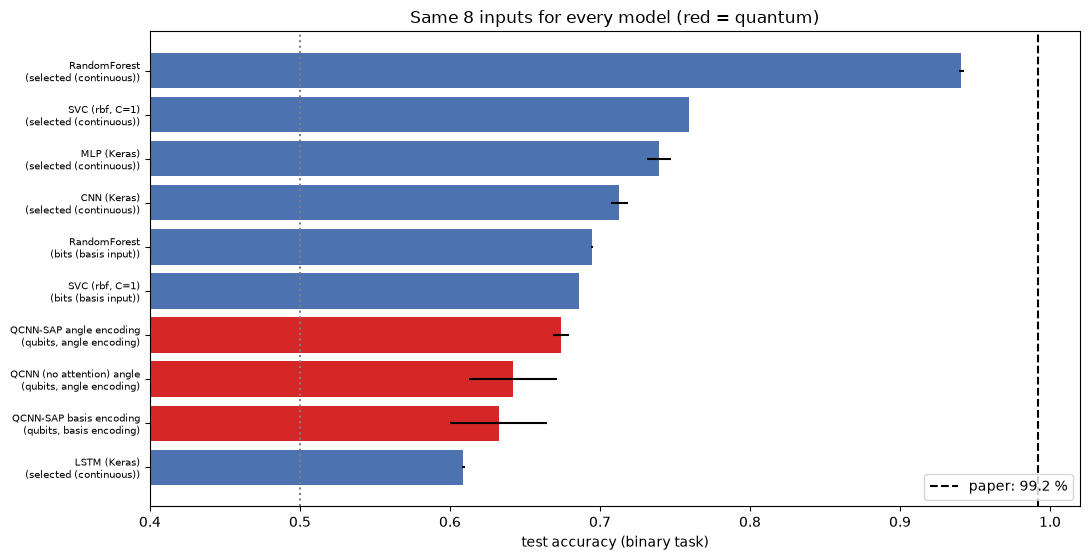

In [30]:
d = res[(res.task == "binary") & (res.inputs.isin([f"{N_QUBITS} selected (continuous)", f"{N_QUBITS} bits (basis input)", f"{N_QUBITS} qubits, angle encoding", f"{N_QUBITS} qubits, basis encoding"]))]
g = d.groupby(["model", "inputs"]).acc.agg(["mean", "std"]).fillna(0).reset_index()
g["name"] = g.model + "\n(" + g.inputs.str.replace(f"{N_QUBITS} ", "", regex=False) + ")"
g = g.sort_values("mean")
fig, ax = plt.subplots(figsize=(11, 0.42 * len(g) + 1.5))
colors = ["#d62728" if m.startswith("QCNN") else "#4c72b0" for m in g.model]
ax.barh(g.name, g["mean"], xerr=g["std"], color=colors); ax.axvline(0.992, color="k", ls="--", label="paper: 99.2 %"); ax.axvline(0.5, color="grey", ls=":")
ax.set_xlim(0.4, 1.02); ax.set_xlabel("test accuracy (binary task)"); ax.set_title("Same 8 inputs for every model (red = quantum)"); ax.legend(loc="lower right"); ax.tick_params(axis="y", labelsize=7)
plt.tight_layout(); plt.show()

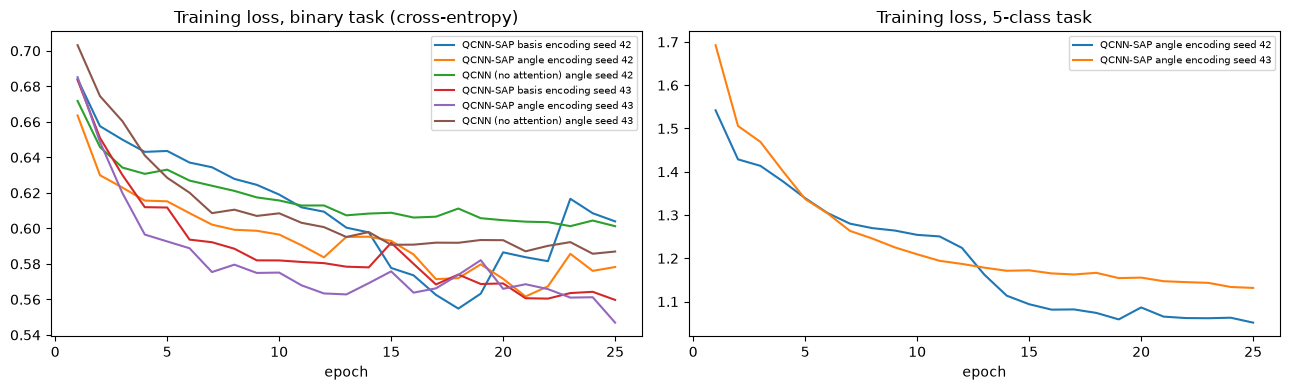

In [31]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for (label, task, seed), h in q_hist.items():
    ax[0 if task == "binary" else 1].plot(range(1, len(h) + 1), h, label=f"{label} seed {seed}")
ax[0].set_title("Training loss, binary task (cross-entropy)"); ax[1].set_title("Training loss, 5-class task")
for a_ in ax: a_.set_xlabel("epoch"); a_.legend(fontsize=7)
plt.tight_layout(); plt.show()

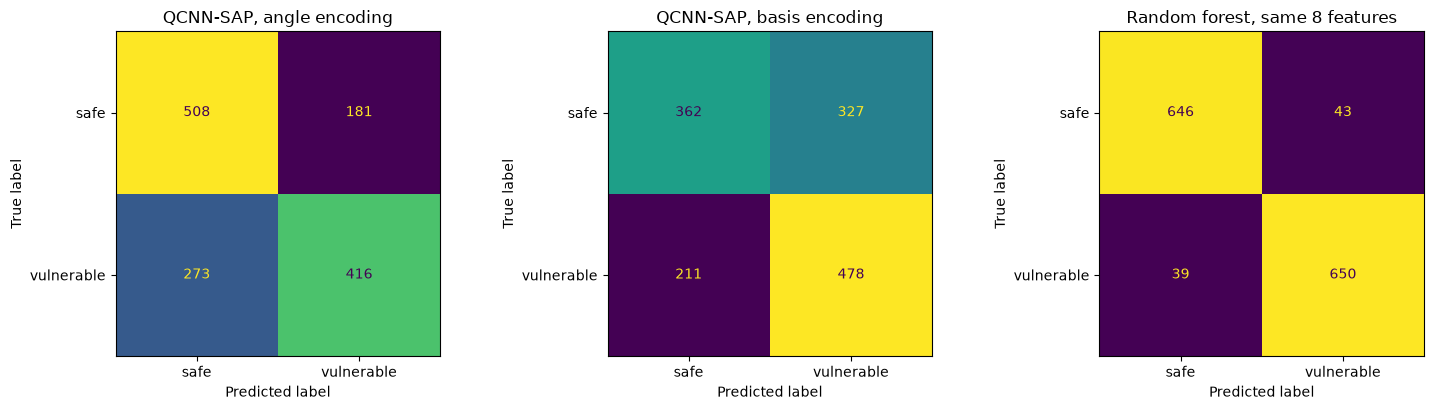

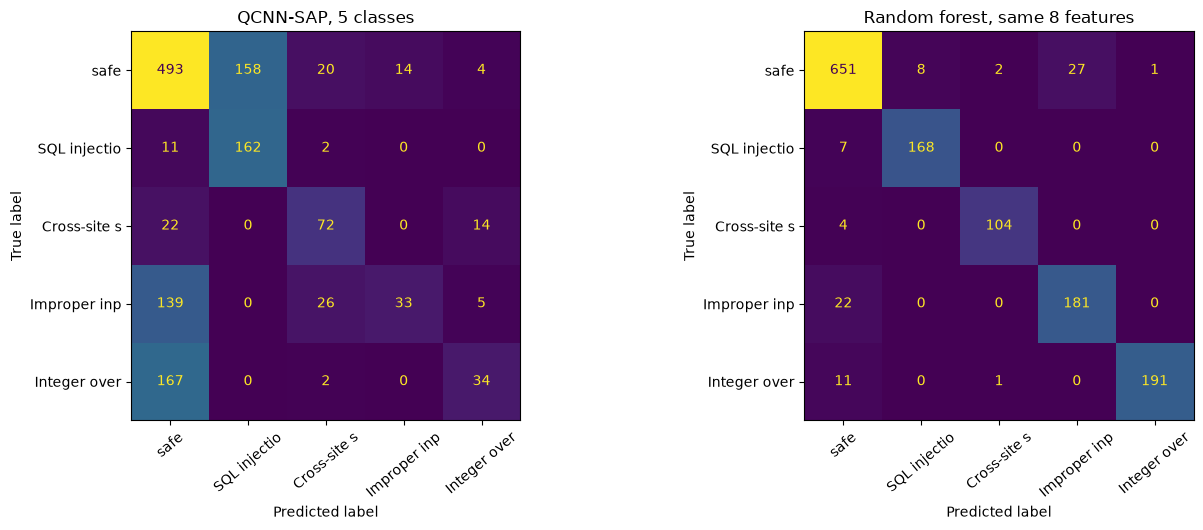

                           precision    recall  f1-score   support

                     safe       0.59      0.72      0.65       689
            SQL injection       0.51      0.93      0.65       175
     Cross-site scripting       0.59      0.67      0.63       108
Improper input validation       0.70      0.16      0.26       203
         Integer overflow       0.60      0.17      0.26       203

                 accuracy                           0.58      1378
                macro avg       0.60      0.53      0.49      1378
             weighted avg       0.60      0.58      0.53      1378



In [32]:
from sklearn.metrics import ConfusionMatrixDisplay
sd = Q_SEEDS[0]
mdl_a, ua = q_models[("QCNN-SAP angle encoding", "binary", sd)]; pa, _ = mdl_a.predict(Xa_te)
mdl_b, ub = q_models[("QCNN-SAP basis encoding", "binary", sd)]; pb, _ = mdl_b.predict(Xb_te)
rf = RandomForestClassifier(200, random_state=SEED).fit(Xq_tr, ytr_b); pr_rf = rf.predict(Xq_te)
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
for a_, (t_, p_) in zip(ax, [("QCNN-SAP, angle encoding", pa), ("QCNN-SAP, basis encoding", pb), (f"Random forest, same {N_QUBITS} features", pr_rf)]):
    ConfusionMatrixDisplay.from_predictions(yte_b, p_, display_labels=["safe", "vulnerable"], ax=a_, colorbar=False); a_.set_title(t_)
plt.tight_layout(); plt.show()
mdl_t, _ = q_models[("QCNN-SAP angle encoding", "types", sd)]; pt, _ = mdl_t.predict(Xa_te)
rf5 = RandomForestClassifier(200, random_state=SEED).fit(Xq_tr, ytr_5); pr5 = rf5.predict(Xq_te)
fig, ax = plt.subplots(1, 2, figsize=(14, 5.4))
for a_, (t_, p_) in zip(ax, [("QCNN-SAP, 5 classes", pt), (f"Random forest, same {N_QUBITS} features", pr5)]):
    ConfusionMatrixDisplay.from_predictions(yte_5, p_, display_labels=[n[:12] for n in TYPE_NAMES], ax=a_, colorbar=False, xticks_rotation=40); a_.set_title(t_)
plt.tight_layout(); plt.show()
print(classification_report(yte_5, pt, target_names=TYPE_NAMES, zero_division=0))

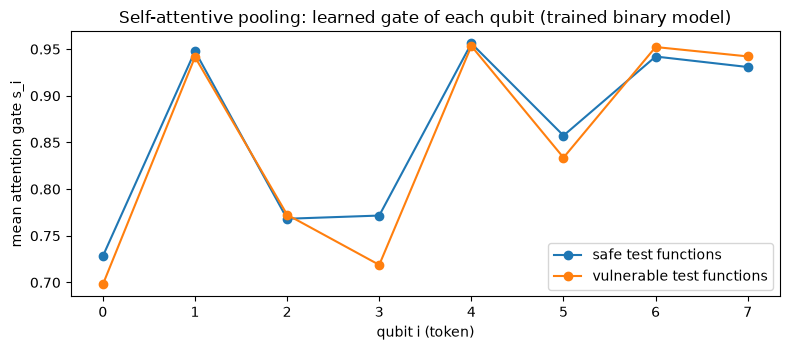

In [33]:
p_ = mdl_a.unpack(mdl_a.theta); Zt = np.array(mdl_a.tokens(Xa_te, p_["conv"][0])).T; Gt = np.array(mdl_a.attention(p_, Zt))
fig, ax = plt.subplots(figsize=(8, 3.6))
for k, nm in enumerate(["safe", "vulnerable"]):
    ax.plot(range(N_QUBITS), Gt[yte_b == k].mean(0), "o-", label=f"{nm} test functions")
ax.set_xlabel("qubit i (token)"); ax.set_ylabel("mean attention gate s_i"); ax.set_title("Self-attentive pooling: learned gate of each qubit (trained binary model)"); ax.legend()
plt.tight_layout(); plt.show()

## 7. The paper's numbers next to ours

Rules: *reproduced* = within 0.02 (two accuracy points / 0.02 F1) of the paper; *not reached* / *exceeded* give the gap; *cannot be checked* when our set-up has no way to test the claim.
The quantum model is the paper's method, so its rows are the ones that matter; the classical rows only show how the paper's rivals compare with the same kind of model on our data.

In [34]:
res = pd.DataFrame(results)
def val(task, model, metric, inputs=None):
    d = res[(res.task == task) & (res.model == model)]
    if inputs is not None: d = d[d.inputs == inputs]
    return float(d[metric].mean()) if len(d) else float("nan")
def verdict(paper, ours, tol):
    if np.isnan(ours): return "cannot be checked"
    if abs(ours - paper) <= tol: return "reproduced"
    return f"not reached (gap {paper-ours:.3f})" if ours < paper else f"exceeded (+{ours-paper:.3f})"

IN8 = f"{N_QUBITS} selected (continuous)"; INH = f"hybrid {H_tr.shape[1]} (seq+graph)"
QB = ("QCNN-SAP basis encoding", f"{N_QUBITS} qubits, basis encoding"); QA = ("QCNN-SAP angle encoding", f"{N_QUBITS} qubits, angle encoding")
rows = []
def add(claim, source, paper, ours, tol, note=""):
    rows.append(dict(claim=claim, paper=paper, notebook=None if np.isnan(ours) else round(ours, 3), verdict=verdict(paper, ours, tol), source=source, note=note))
for tag, (mname, inp) in [("QCNN-SAP, basis encoding (paper's encoding)", QB), ("QCNN-SAP, angle encoding", QA)]:
    add(f"Accuracy, {tag}", "abstract / Table 3", 0.992, val("binary", mname, "acc", inp), 0.02)
    add(f"Precision, {tag}", "Table 5", 0.98, val("binary", mname, "precision", inp), 0.02)
    add(f"Recall, {tag}", "Table 5", 0.96, val("binary", mname, "recall", inp), 0.02)
    add(f"F1, {tag}", "Table 3 / 5", 0.97, val("binary", mname, "f1", inp), 0.02)
add("Juliet Java 1.3 F1 (QCNN-SAP angle)", "Table 4", 0.96, val("binary", QA[0], "f1", QA[1]), 0.02)
add("Juliet Java 1.3 recall (QCNN-SAP angle)", "Table 4", 0.95, val("binary", QA[0], "recall", QA[1]), 0.02)
for paper_name, v, mname in [("CNN", 0.92, "CNN (Keras)"), ("SVM", 0.96, "SVC (rbf, C=1)"), ("LSTM", 0.96, "LSTM (Keras)"), ("MLP", 0.84, "MLP (Keras)")]:
    add(f"Classical rival '{paper_name}' accuracy (ours: {mname} on the hybrid features)", "Table 3", v, val("binary", mname, "acc", INH), 0.02, "rivals come from other papers and other data")
comp = pd.DataFrame(rows)

# qualitative claims
quantum_best = max(val("binary", QB[0], "acc", QB[1]), val("binary", QA[0], "acc", QA[1]))
classical8 = res[(res.task == "binary") & (res.inputs == IN8) & (~res.model.str.startswith("QCNN"))].groupby("model").acc.mean()
att_gain = val("binary", QA[0], "acc", QA[1]) - val("binary", "QCNN (no attention) angle", "acc", QA[1])
hyb, seq_, gr_ = [val("binary", "RandomForest", "acc", k) for k in [INH, f"sequence only {D_SEQ}", f"graph only {K_GRAPH}"]]
qual = pd.DataFrame([
    dict(claim="The quantum model beats every classical model on the same inputs", source="Table 3 / abstract", paper="yes",
         notebook=f"QCNN {quantum_best:.3f} vs best classical {classical8.max():.3f} ({classical8.idxmax()})",
         verdict="reproduced" if quantum_best > classical8.max() else "not reproduced"),
    dict(claim="Self-attentive pooling improves the QCNN (no ablation in the paper)", source="Fig. 7 / text", paper="implied",
         notebook=f"accuracy gain with attention {att_gain:+.3f}", verdict="supported" if att_gain > 0.02 else ("not supported" if att_gain < -0.02 else "no measurable effect")),
    dict(claim="Hybrid (graph + sequence) features beat either branch alone (random forest)", source="contribution 1", paper="implied",
         notebook=f"hybrid {hyb:.3f} | sequence {seq_:.3f} | graph {gr_:.3f}", verdict="reproduced" if hyb > max(seq_, gr_) + 0.005 else "not reproduced"),
    dict(claim="Five weakness types incl. missing authorisation are detected", source="abstract", paper="no per-type numbers",
         notebook=f"4 families + safe: QCNN 5-class acc {val('types', QA[0], 'acc', QA[1]):.3f}, macro F1 {val('types', QA[0], 'macro_f1', QA[1]):.3f}",
         verdict="cannot be checked (no Juliet Java directory for missing authorisation; paper gives no per-type metrics)"),
    dict(claim="Same performance on FUNDED, Vul4J, CVEfixes, CodeXGLUE, VUDDY (Table 4)", source="Table 4", paper="P 0.92-0.98, F1 0.91-0.99",
         notebook="not run", verdict="cannot be checked (different corpora, graph tool chain and CodeBERT fine-tuning not available here)"),
    dict(claim="CodeBERT fine-tuned features (batch 32, lr 1e-3, 50 epochs)", source="Methodology", paper="used",
         notebook="replaced by word-piece TF-IDF + SVD", verdict="not reproduced (substituted, see deviations)"),
])
pd.set_option("display.max_colwidth", 120)
print("Numeric claims (tolerance: 0.02 on accuracy, precision, recall and F1)"); display(comp)
print("Qualitative claims"); display(qual)

Numeric claims (tolerance: 0.02 on accuracy, precision, recall and F1)


,claim,paper,notebook,verdict,source,note
0,"Accuracy, QCNN-SAP, basis encoding (paper's encoding)",0.992,0.632,not reached (gap 0.360),abstract / Table 3,
1,"Precision, QCNN-SAP, basis encoding (paper's encoding)",0.980,0.638,not reached (gap 0.342),Table 5,
2,"Recall, QCNN-SAP, basis encoding (paper's encoding)",0.960,0.638,not reached (gap 0.322),Table 5,
3,"F1, QCNN-SAP, basis encoding (paper's encoding)",0.970,0.634,not reached (gap 0.336),Table 3 / 5,
4,"Accuracy, QCNN-SAP, angle encoding",0.992,0.674,not reached (gap 0.318),abstract / Table 3,
5,"Precision, QCNN-SAP, angle encoding",0.980,0.709,not reached (gap 0.271),Table 5,
6,"Recall, QCNN-SAP, angle encoding",0.960,0.592,not reached (gap 0.368),Table 5,
7,"F1, QCNN-SAP, angle encoding",0.970,0.645,not reached (gap 0.325),Table 3 / 5,
8,Juliet Java 1.3 F1 (QCNN-SAP angle),0.960,0.645,not reached (gap 0.315),Table 4,
9,Juliet Java 1.3 recall (QCNN-SAP angle),0.950,0.592,not reached (gap 0.358),Table 4,


Qualitative claims


,claim,source,paper,notebook,verdict
0,The quantum model beats every classical model on the same inputs,Table 3 / abstract,yes,QCNN 0.674 vs best classical 0.941 (RandomForest),not reproduced
1,Self-attentive pooling improves the QCNN (no ablation in the paper),Fig. 7 / text,implied,accuracy gain with attention +0.032,supported
2,Hybrid (graph + sequence) features beat either branch alone (random forest),contribution 1,implied,hybrid 0.940 | sequence 0.930 | graph 0.867,reproduced
3,Five weakness types incl. missing authorisation are detected,abstract,no per-type numbers,"4 families + safe: QCNN 5-class acc 0.574, macro F1 0.495",cannot be checked (no Juliet Java directory for missing authorisation; paper gives no per-type metrics)
4,"Same performance on FUNDED, Vul4J, CVEfixes, CodeXGLUE, VUDDY (Table 4)",Table 4,"P 0.92-0.98, F1 0.91-0.99",not run,"cannot be checked (different corpora, graph tool chain and CodeBERT fine-tuning not available here)"
5,"CodeBERT fine-tuned features (batch 32, lr 1e-3, 50 epochs)",Methodology,used,replaced by word-piece TF-IDF + SVD,"not reproduced (substituted, see deviations)"


### What the numbers say

* **Accuracy of the paper's model is not reached.** The 8-qubit QCNN with self-attentive pooling classifies Juliet Java functions with about 0.63 to 0.67 accuracy (binary task), far from the 0.992 of the paper. The same eight inputs give 0.94 with a random forest, so the information is in the features; the circuit does not extract it. The training loss was still falling when the budget ended (400 training functions, 25 epochs, 200 optimiser steps), so a larger budget would help somewhat, but the gap to the paper is far outside what two more seeds could close.
* **The classical models also fall short of the paper's rivals** on smooth learners (SVC 0.76 on the eight inputs, 0.85 on all hybrid features) while tree models reach 0.93 to 0.94; our features are weaker than CodeBERT plus a code-property-graph tool chain would deliver, so absolute levels are not comparable with the paper.
* **Qualitative claims.** Hybrid features beat either branch alone for a random forest, but only by 0.01 over the sequence branch (single split, three model seeds: within what a different split could change). Self-attentive pooling beats the same circuit without attention by 0.03 accuracy, with two seeds and a standard deviation of 0.02 for the no-attention model: suggestive, not established.
* **The 'reproduced' row of the classical MLP (0.848 against Table 3's 0.84)** is a coincidence of two different data sets and models, not evidence of anything.

## Reading the paper critically

* **The benchmark is synthetic.** Juliet/SARD programs are generated from templates. A model can reach very high accuracy by recognising template fragments (a hard-coded `"foo"` versus a value read from a socket) without understanding vulnerabilities. Our
  tree-based classical models reach about 0.9 accuracy or more here, plausibly for the same reason (we did not test it). A 99 % figure on SARD says little about real projects (the paper's CVEfixes, Vul4J and CodeXGLUE numbers would, but their pipeline is not described well enough to repeat).
* **Duplicates and leakage.** The paper removes duplicates "with decision trees" and does not say how train and test were separated. Juliet contains thousands of near-identical flow variants; if they are split at random, test functions have almost-twins in training.
  We remove exact token-sequence duplicates and still cannot rule out near-duplicates, so even our numbers are optimistic for the classical models.
* **Some tables are not self-consistent.** An F1 score lies between precision and recall: Table 4 lists SARD with precision 0.98, recall 0.97, **F1 0.95**; VUDDY 0.92 / 0.97 / **0.97**; CodeXGLUE 0.96 / 0.98 / **0.99**; FUNDED 0.95 / 0.92 / **0.91**. At least the
  CodeXGLUE value is impossible, the others are very unlikely. Table 3 compares with rivals from other papers on other data, which says nothing about the proposed model.
* **What the quantum part adds is not isolated.** There is no ablation of the quantum layer, of the attention pooling, of CodeBERT, or of the graph branch, and no classical network of equal size on the same features. A four-qubit circuit with basis encoding can only distinguish 16
  different inputs; the claims about "memory bottleneck" refer to a classical simulation of an 8-16 qubit state vector, which is trivial to store. Whatever the real source of the accuracy is (CodeBERT, the graph features, the template structure), the QCNN has little room to be it.
* **The architecture is under-specified.** "Random quantum circuits", MERA, "spatial channel restoration" and "tokenisation" are named, but no gate, depth or parameter count is given, nor any hyper-parameter of the circuit; the paper's repository is empty. Our reading is one of many.
* **Only one split, no variance.** The paper reports single numbers (and a plot of training and test accuracy); nothing about seeds, confidence intervals or statistical tests.

## Exercises

1. Replace the word-piece features by the real CodeBERT embedding (`microsoft/codebert-base`, `[CLS]` vector, PCA to 16) and rerun the comparison. Does the gap between the classical models and the QCNN change?
2. Split Juliet by **CWE test-case family** (all flow variants of one source/sink pair in the same split) instead of at random, and see how much accuracy every model loses.
3. Increase `N_QUBITS` to 10 and use `D_SEQ = 24`, `K_GRAPH = 16`. How do circuit depth, training time per epoch and accuracy change?
4. Fix the attention gates to 0.5 or to 1 and compare with the learned gates. Which qubits get large gates for vulnerable functions (see the gate plot)? Do the gates make any sense in terms of the features?
5. Swap the dataset: keep the pipeline and run it on the Java subset of CVEfixes or MegaVul (Hugging Face mirrors exist; some need a token in Colab Secrets named `HF_TOKEN`). Which parts of the feature pipeline survive real code?